# Guess Who?
### Can a model tell my writing apart from my classmate's, and what gives us away?

My roommate, friend, and CS156-survivor Pedro and I have worked on the same Minerva assignments for three years: the same Cornerstone essays, Formal Analyses workbooks, and many CS problem sets. That makes our archives a fairly controlled experiment in **stylometry** (authorship attribution): whatever separates our texts should be mostly *how* we write rather than *what* we were asked. The field is old. Mosteller and Wallace (1964) settled the disputed *Federalist Papers* by counting words like *upon* and *whilst*, because the most frequent, least meaningful words are used at a rate that is personal, unconscious and largely independent of topic. Having worked on a large authorship-disambiguation project in an internship, I was curious how different text representations and models compare.

I ask three questions. **(1)** Can a classifier tell which of us wrote an assignment it has never seen, and how much text does it need? **(2)** Is it recognising *style* or just *topic*? To test this, one version of the input masks every content word. **(3)** What exactly gives each of us away?

Pedro agreed to the use of his assignments. Only aggregate statistics and single words are shown, no passages of his writing, and names are removed before modelling.

### Code repository

**GitHub:** `https://github.com/fabiansteinmetz/CS156`

The repository contains this notebook. The data are on [Google Drive](https://drive.google.com/drive/folders/1A1x60hjhVbAuhYTyqkpRPFHQkt6Bv4i1?usp=drive_link), shared only with Minerva accounts, because Pedro and I agreed not to publish them on GitHub. To run the notebook, download the `fabi/` and `pedro/` folders into the same directory as this file, and install `pdftotext` from poppler (`brew install poppler`, https://formulae.brew.sh/formula/poppler).

My work follows the pipeline below.

In [1]:
# installing scikit-learn into the kernel that runs this notebook
import sys
print(sys.executable)                      # shows which python the notebook is using
%pip install scikit-learn

# standard library
import re, subprocess, unicodedata
from pathlib import Path

# data handling, plotting and statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats

# scikit-learn functions are imported in the cell that first uses them

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})  # plot style
COLORS = {"Fabian": "#2a6f97", "Pedro": "#c8553d"}                        # one color per author
MODEL_COLORS = {"NB": "#9ab0c0", "LogReg": "#2a6f97", "SVM": "#14365d"}   # one color per model
ROOT = Path.cwd()                                   # contains fabi/ and pedro/ (one pdf per assignment)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)     # folder for saved figures
RNG = np.random.default_rng(156)                    # fixed seed so every run gives the same numbers

/opt/anaconda3/envs/pymc_env/bin/python
Note: you may need to restart the kernel to use updated packages.


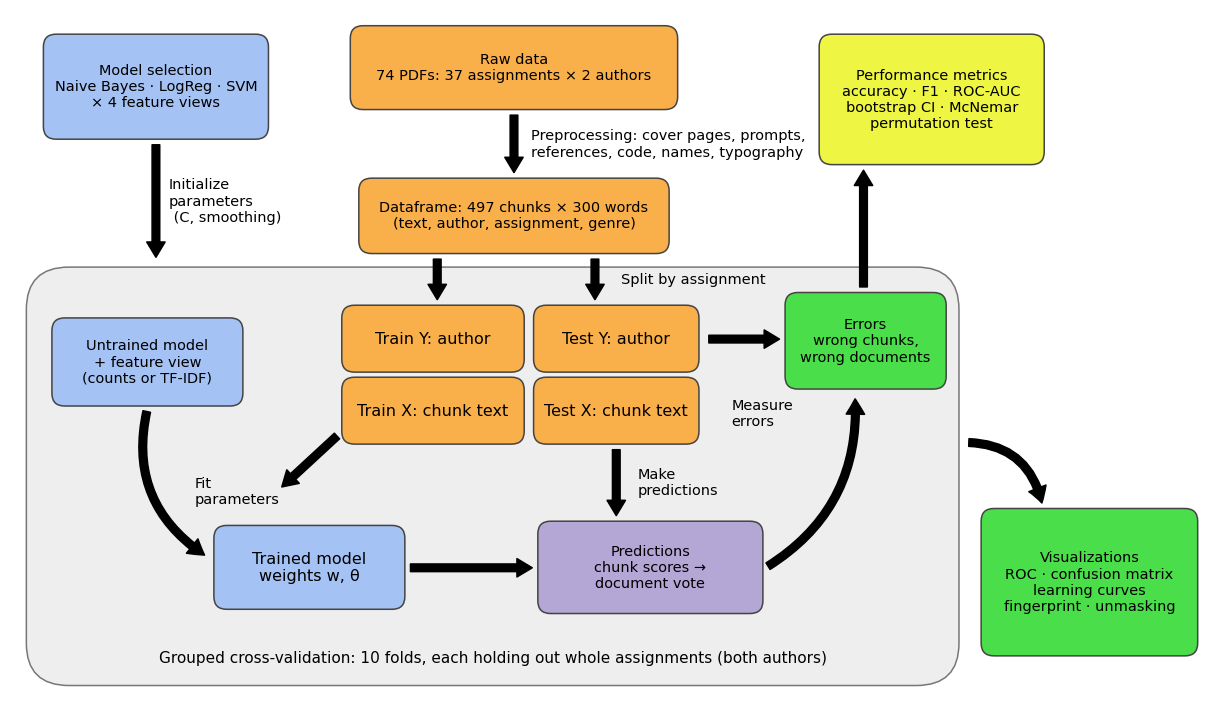

In [2]:

# creating a pipeline plot similar to that of the instructions
fig, ax = plt.subplots(figsize=(14, 8.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 8.2); ax.axis("off")

def box(x, y, w, h, text, color, size=10.5):
    '''creating this so i can create same-style boxes easily'''
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=color, ec="#444"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size)

def arrow(x1, y1, x2, y2, label="", lx=0.15, ly=0, rad=0.0):
    '''creating this so i can create arrows between boxes easily'''
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="simple,head_width=12,head_length=10,tail_width=5", color="black", connectionstyle=f"arc3,rad={rad}"))
    if label:
        ax.text((x1 + x2) / 2 + lx, (y1 + y2) / 2 + ly, label, fontsize=9.5, va="center")

# defining a color-scheme
blue, orange, green, yellow, purple = "#a4c2f4", "#f9b04b", "#4ade4a", "#eef542", "#b4a7d6"

# cross-validation box
ax.add_patch(FancyBboxPatch((0.2, 0.25), 10.9, 4.9, boxstyle="round,pad=0.02,rounding_size=0.5", fc="#eeeeee", ec="#777"))
ax.text(5.65, 0.5, "Grouped cross-validation: 10 folds, each holding out whole assignments (both authors)",
        ha="center", fontsize=10)

# arranging the placement of the boxes by hand
box(0.4, 6.7, 2.6, 1.2, "Model selection\nNaive Bayes · LogReg · SVM\n× 4 feature views", blue, 9.5)
arrow(1.7, 6.65, 1.7, 5.25, "Initialize\nparameters\n (C, smoothing)")
box(4.0, 7.05, 3.8, 0.95, "Raw data\n74 PDFs: 37 assignments × 2 authors", orange, 9.5)
arrow(5.9, 7.0, 5.9, 6.25, "Preprocessing: cover pages, prompts,\nreferences, code, names, typography", lx=0.2)
box(4.1, 5.35, 3.6, 0.85, "Dataframe: 497 chunks × 300 words\n(text, author, assignment, genre)", orange, 9.5)

box(0.5, 3.55, 2.2, 1.0, "Untrained model\n+ feature view\n(counts or TF-IDF)", blue, 9.5)
arrow(5.0, 5.3, 5.0, 4.75); arrow(6.85, 5.3, 6.85, 4.75, "Split by assignment", lx=0.3)
box(3.9, 3.95, 2.1, 0.75, "Train Y: author", orange); box(6.15, 3.95, 1.9, 0.75, "Test Y: author", orange)
box(3.9, 3.1, 2.1, 0.75, "Train X: chunk text", orange); box(6.15, 3.1, 1.9, 0.75, "Test X: chunk text", orange)
arrow(3.85, 3.2, 3.15, 2.55, "Fit\nparameters", lx=-1.35, ly=-0.35)
arrow(1.6, 3.5, 2.3, 1.75, rad=0.35)
box(2.4, 1.15, 2.2, 0.95, "Trained model\nweights w, θ", blue)
arrow(7.1, 3.05, 7.1, 2.2, "Make\npredictions", lx=0.25)
arrow(4.65, 1.62, 6.15, 1.62)
box(6.2, 1.1, 2.6, 1.05, "Predictions\nchunk scores →\ndocument vote", purple, 9.5)
arrow(8.15, 4.32, 9.05, 4.32)
box(9.1, 3.75, 1.85, 1.1, "Errors\nwrong chunks,\nwrong documents", green, 9.5)
arrow(8.85, 1.62, 9.9, 3.65, rad=0.3)
ax.text(8.45, 3.3, "Measure\nerrors", fontsize=9.5)

arrow(10.0, 4.9, 10.0, 6.35)
box(9.5, 6.4, 2.6, 1.5, "Performance metrics\naccuracy · F1 · ROC-AUC\nbootstrap CI · McNemar\npermutation test", yellow, 9.5)
arrow(11.2, 3.1, 12.1, 2.35, rad=-0.4)
box(11.4, 0.6, 2.5, 1.7, "Visualizations\nROC · confusion matrix\nlearning curves\nfingerprint · unmasking", green, 9.5)

fig.savefig(FIG / "pipeline.png", bbox_inches="tight")
plt.show()

## 3. Data Pre-Processing

My data are the individual assignments Pedro and I submitted in 13 courses (eight Cornerstones in year 1; CS111, CS114, CS146, AH111 and SS111 in years 2–3), exported from Forum as one PDF per assignment (`COURSE - N.pdf`). Nine group assignments are excluded for both of us, because they contain other students' writing. That leaves **37 assignments written by both of us, 74 documents**.

The PDFs mix our writing with text neither of us wrote: cover pages, prompts, workbook questions, AI-use statements, references and code. Several of Pedro's documents start with the same Grammarly disclosure, which a model would happily learn as "the Pedro feature". Four steps remove everything that is not our own prose:

1. **Read** each PDF with `pdftotext`, page by page.
2. **Layout-specific extraction:** drop cover pages; in Forum workbooks keep only the answers.
3. **Sentence-level cleaning:** remove instructions, task statements, citations, quotes, URLs, hashtags, names, references and captions.
4. **Duplicates and typography:** delete sentences that appear in both of our versions, and normalise punctuation that depends on the editor rather than the writer.

In [3]:
# manually defining which assignments to use
# group assignments are not written by one person, so they are excluded for both authors
# while they were initially part of the data, i decided not to keep them in the folders because of privacy reasons

# pedro took AH111 in a different term, so his file numbers differ from mine: his file name -> my assignment id
# None = skip the file (his AH111 - 2 is the collaborative letter portfolio, a group assignment)
PEDRO_RENAME = {"AH111 - 2": None, "AH111 - 5": "AH111 - 2"}

# genres used for reporting (workbooks are detected automatically; everything else is an essay)
GENRE = {"technical": ["CS111 - 1", "CS111 - 4", "CS114 - 1", "CS114 - 2", "CS114 - 3", "CS114 - 4",
                       "CS146 - 2", "CS146 - 3"],
         "reflection": ["CS111 - 3", "CS114 - 5", "CS146 - 4", "CX51 - 3", "MC50 - 1", "MC50 - 4",
                        "MC51 - 1", "MC51 - 4"]}


def pdf_pages(path, layout=False):
    # pdftotext separates pages with a form feed; -layout keeps indentation (needed for workbooks)
    cmd = ["pdftotext"] + (["-layout"] if layout else []) + [str(path), "-"]   # "-" = write to stdout
    output = subprocess.run(cmd, capture_output=True, text=True, check=True).stdout  # run pdftotext
    return output.split("\f")                                                 # one string per page


def is_workbook(path):
    # after manual inspection, i found that the format Question X of Y is used in all the workbooks
    return bool(re.search(r"Question \d+ of \d+", "".join(pdf_pages(path))))

**Layout-specific extraction.** Essays, problem sets and reflections lose their cover page (title, course, professor, date, AI-use statement); short LaTeX documents that start on page 1 lose only their header block. Running headers, page numbers, reference lists and lines that do not look like prose (under 60% letters, code syntax) are dropped. In **Forum workbooks** the answer is indented further than its "Question N of M" header, so only the further-indented lines are kept.

In [4]:
# layout-specific extraction

# the following need to be removed as they would likely let classifiers pick up on features beyond our writing styles
# months we took the class in
MONTHS = "Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec|January|February|March|April|June|July|August|September|October|November|December"
# dates we submitted assignments
DATE_RE = re.compile(rf"\b({MONTHS})\.? \d{{1,2}}(st|nd|rd|th)?,? (20\d\d)\b")
# header row with professor and course information
HEADER_RE = re.compile(r"Minerva|Prof\.|University|Name:|@\d|\b(Spring|Fall) 20\d\d|^\s*(CS|AH|SS|CX|EA|FA|MC)\d+")
# reference list does not have anything to do with writing styles
REFERENCE_HEADING = re.compile(r"^(references?|reference list|works cited|bibliography|sources)\s*:?$", re.I)
# we want to identify where the appendix starts after the references because it includes written text again
APPENDIX_HEADING = re.compile(r"^appendi(x|ces)\b", re.I)


def is_prose_line(line):
    # returns True if it passes all of the checks, e.g. "is this section a code notebook?"
    s = line.strip()                                                      # drop surrounding whitespace
    if not s or s.isdigit():                                              # empty line, page number
        return False
    if re.match(r"^\d+\s{2,}\S", line.lstrip("​")):                  # numbered code-cell line
        return False
    if re.match(r"^\d{1,3}\s+\S", s) and re.search(r"[_=()#\[\]]", s):   # same, tighter spacing
        return False
    if re.search(r"In \[\s*\d*\s*\]", s):                                 # notebook cell marker
        return False
    chars = [c for c in s if not c.isspace()]                             # all visible characters
    if sum(c.isalpha() for c in chars) / max(len(chars), 1) < 0.6:       # mostly math, numbers, symbols
        return False
    if len(s.split()) < 3 and not re.search(r"[.?!:]$", s):              # equation fragments
        return False
    if re.search(r"(\bdef |\bimport |\breturn\b|==|\+=|\bnp\.|\bplt\.|\[\d+\]:)", s):   # code
        return False
    return True                                                           # looks like a line of prose


def drop_first_page(pages):
    # drop the first page as explained before
    first = pages[0]
    if len(first.split()) <= 60 or "INSTRUCTIONS" in first:   # cover page or google-doc template page
        return pages[1:]
    lines = first.splitlines()                                # text starts on page 1: drop the header block only
    header_end = max([i for i, l in enumerate(lines[:12]) if HEADER_RE.search(l) or DATE_RE.search(l)], default=0)  # last header line
    return ["\n".join(lines[header_end + 1:])] + pages[1:]    # page 1 without its header, then the rest


# given that text is either in an essay (latex or google docs), or a forum workbook, we need to extract them differently

def extract_essay(path):
    # extract text from an essay
    lines = "\n".join(drop_first_page(pdf_pages(path))).splitlines()     # all lines after the cover page
    counts = pd.Series([l.strip() for l in lines if l.strip()]).value_counts()  # how often each line occurs
    running_headers = set(counts[counts >= 3].index)          # identical lines repeated on many pages
    kept, in_references = [], False
    for line in lines:
        s = line.strip()
        if REFERENCE_HEADING.match(s):                        # everything after this is the reference list
            in_references = True
            continue
        if in_references and APPENDIX_HEADING.match(s):       # appendices after the references are ours again
            in_references = False
        if not in_references and s not in running_headers and is_prose_line(line):
            kept.append(s)                                    # keep the line
    return " ".join(kept)                                     # one string per document


def extract_workbook(path):
    # extract response text from a workbook
    junk = re.compile(r"^(Normal|Drop or upload|.*\(\d+ kB\)|Python 3 \(|.*Run All Cells|Original Submission|Explore)\b")  # forum interface text
    kept, prompt_indent = [], None
    for line in "\n".join(pdf_pages(path, layout=True)).splitlines():   # layout mode keeps the indentation
        s = line.strip()
        if not s:                                             # skip empty lines
            continue
        indent = len(line) - len(line.lstrip(" "))            # number of leading spaces
        if re.match(r"\s*Question \d+ of \d+", line):
            prompt_indent = indent                            # prompt printed at this indent, answers further in
            continue
        if prompt_indent is not None and indent > prompt_indent + 1 and not junk.match(s) and is_prose_line(line):
            kept.append(s)                                    # indented further than the prompt = our answer
    return " ".join(kept)

**Sentence-level cleaning.** URLs, HC hashtags, parenthetical citations, quotations of five or more words, notebook interface text and the names of students and professors are removed first. The text is then split into sentences, and instructions, AI-use statements, copied task statements ("Explain the concept of…"), reference entries and captions are dropped. I chose these rules by inspecting the assignments; more rules would likely catch more.

In [5]:
# sentence-level cleaning
# names of both authors, removed so the model cannot simply read who we are
NAMES = r"\b(Fabian|Fabi|Steinmetz|Pedro|Henrique|Gon[cç]alves|Paiva)\b"
# instructions, word limits and ai-use statements that are not our own writing
INSTRUCTION_RE = re.compile(
    r"(AI note|AI statement|Grammarly|No AI tools|AI tools? (was|were) used|you must|you should|you will need|"
    r"choose one of|write an? \d|\d+[- –]to[- –]\d+[- ]words?|\(\s*<?\s*\d+ words\)|\(\d+\s*[-–]\s*\d+ words\)|"
    r"include a footnote|footnote explaining|LO application footnote|sentences are typical|Argument choices|"
    r"Resource choices|^Session \d+:|^Question \d+|^\(Part \d\)|word length|word count|do not delete|"
    r"Link to your copy|remember to|^Option [A-D]\b)", re.IGNORECASE)
# task statements copied from problem sets, e.g. "explain the concept of ..."
TASK_RE = re.compile(r"^(\(?[0-9a-z]{1,2}[.)]\s*)*(Explain|Describe|Select|Identify|Discuss|Compute|Calculate|Find|"
                     r"Make sure|Provide|Justify|Write|Choose|Compare|Determine|Prove|Derive|Interpret|Show that|"
                     r"State|List|Give|Include|Briefly)\b")
# numbered questions copied from problem sets, e.g. "1. how is ... ?"
NUMBERED_QUESTION_RE = re.compile(r"^\(?[0-9]{1,2}[a-z]?[.)].*\?$")
# reference-list entries that survive without a "references" heading
REFERENCE_ENTRY_RE = re.compile(r"(\bpp\.\s*\d|\(Eds?\.\)|University Press|Retrieved from|\bVol\.\s*\d|\b\d+\(\d+\),\s*\d)")
# jupyter and forum interface text inside workbook pdfs
UI_RE = re.compile(r"\(\d+MB RAM\)|Kernel (Stopped|Idle|Busy)|Python 3|In \[\s*\d*\s*\]:?|Out\[\d+\]:?|Run All Cells|\| Edit")


def clean_sentences(text):
    # i used parts of this from my previous internship work
    text = text.replace("​", " ").replace("­", "")                    # zero-width spaces, soft hyphens
    text = re.sub(r"(\w)-\s+(\w)", r"\1\2", text)                               # re-join hyphenated words
    text = re.sub(r"https?://\S+|www\.\S+|doi:\S+|\S+@\S+", " ", text)          # links, emails
    text = re.sub(r"#\w+", " ", text)                                           # HC / LO hashtags
    text = re.sub(r"\([^()]*\b(1[89]|20)\d\d[a-z]?\b[^()]*\)", " ", text)       # (Author, 2020)
    text = re.sub(r"\([^()]*n\.d\.[^()]*\)", " ", text)                         # (Author, n.d.)
    text = re.sub(r"[“\"][^”\"]{0,400}[”\"]", lambda m: m.group(0) if len(m.group(0).split()) < 5 else " ", text)  # quotes of 5+ words
    text = re.sub(NAMES, " ", text)                                             # our names
    text = re.sub(r"Prof\.\s*(?:[A-Z]\.\s*)?[A-Z][\w’'-]+", "the professor", text)  # professors' names
    text = UI_RE.sub(" ", text)                                                 # notebook interface text
    text = re.sub(r"\s+", " ", text).strip()                                    # collapse whitespace
    sentences = [s.strip(" •") for s in re.split(r"(?<=[.!?])\s+(?=[A-Z“\"(0-9•])", text)]  # split into sentences
    return [s for s in sentences if s                                           # keep a sentence only if it is
            and not INSTRUCTION_RE.search(s) and not TASK_RE.match(s) and not NUMBERED_QUESTION_RE.match(s)  # not a prompt,
            and not REFERENCE_ENTRY_RE.search(s) and not re.match(r"^(Figure|Fig\.|Table)\s*\d+", s)]        # reference or caption

**Duplicated sentences and typography.** A sentence that appears in *both* of our versions of an assignment is most likely prompt text rather than our own writing. For assignment $a$, let $S_F(a)$ and $S_P(a)$ be the sets of sentences of at least six words in my and Pedro's versions, lower-cased and without punctuation ($\operatorname{norm}$). A sentence $s$ is kept only if

$$\operatorname{norm}(s)\notin S_F(a)\cap S_P(a).$$

The six-word minimum keeps short common sentences ("This is shown below.") from being deleted. Typography also differs by editor: my essays mostly use curly apostrophes and Pedro's straight ones. That is an automatic setting, not a writing choice, but a character-level model could identify us from it alone, so every model sees normalised text.

In [6]:
# typography and duplicate sentences
def normalize_typography(text):
    text = unicodedata.normalize("NFKC", text)  # ligatures: ﬁ -> fi
    text = re.sub(r"[‘’‚‛′`´]", "'", text)  # curly apostrophes
    text = re.sub(r"[“”„‟″]", '"', text)         # curly double quotes - especially common in german
    text = re.sub(r"\s*[–—―]\s*", " - ", text)    # en and em dashes
    text = text.replace("…", "...")                # ellipsis character
    text = re.sub(r"[^\x00-\x7fÀ-ɏ]", " ", text)   # symbols outside latin script
    return re.sub(r"\s+", " ", text).strip()      # collapse whitespace


def remove_shared_sentences(df):
    # a sentence that appears in both of our versions of an assignment is prompt text, not style
    norm = lambda s: re.sub(r"[^a-z0-9 ]", "", s.lower()).strip()           # compare without case and punctuation
    for _, group in df.groupby("assignment"):                               # both versions of one assignment
        shared = set.intersection(*[{norm(s) for s in sents if len(s.split()) >= 6} for sents in group.sentences])  # sentences in both
        for idx in group.index:
            df.at[idx, "sentences"] = [s for s in df.at[idx, "sentences"] if norm(s) not in shared]  # drop them
            df.at[idx, "shared_removed"] = len(shared)                       # remember how many were dropped
    return df


def build_corpus(root):
    # call the previous functions on every pdf and collect one row per document
    rows = []
    for author, folder in [("Fabian", "fabi"), ("Pedro", "pedro")]:
        for pdf in sorted((root / folder).glob("*.pdf")):
            aid = PEDRO_RENAME.get(pdf.stem, pdf.stem) if author == "Pedro" else pdf.stem  # assignment id
            if aid is None:                                                 # file mapped to None = skip
                continue
            workbook = is_workbook(pdf)                                     # pick the right extractor
            raw = extract_workbook(pdf) if workbook else extract_essay(pdf)
            genre = "workbook" if workbook else next((g for g, ids in GENRE.items() if aid in ids), "essay")
            rows.append({"author": author, "assignment": aid, "course": aid.split(" - ")[0], "genre": genre,
                         "raw_words": sum(len(p.split()) for p in pdf_pages(pdf)), "sentences": clean_sentences(raw)})
    df = remove_shared_sentences(pd.DataFrame(rows).assign(shared_removed=0))  # pairwise filter
    df["text_raw_typography"] = df.sentences.apply(" ".join)               # text before typography fix (kept to show the typography counts)
    df["text"] = df.text_raw_typography.apply(normalize_typography)        # text used by every model
    df["words"] = df.text.str.split().str.len()                            # cleaned length
    paired = df.groupby("assignment").author.nunique()                     # keep assignments both of us have
    df = df[df.assignment.isin(paired[paired == 2].index)].drop(columns="sentences")
    return df.sort_values(["assignment", "author"]).reset_index(drop=True)

# calling the functions on our directory
docs = build_corpus(ROOT)
docs["y"] = (docs.author == "Pedro").astype(int)       # label: 1 = pedro, 0 = me
docs["doc"] = docs.author + " | " + docs.assignment    # readable document id

# words before and after cleaning, per author
summary = docs.groupby("author").agg(documents=("doc", "size"), raw_words=("raw_words", "sum"), clean_words=("words", "sum"), median_words=("words", "median"))
summary["kept"] = (summary.clean_words / summary.raw_words).map("{:.0%}".format)  # share of words kept
display(summary)
display(pd.crosstab(docs.genre, docs.author))          # documents per genre and author

,documents,raw_words,clean_words,median_words,kept
author,,,,,
Fabian,37,117689,74496,1735.0,63%
Pedro,37,119818,75078,1808.0,63%


author,Fabian,Pedro
genre,,
essay,17,17
reflection,8,8
technical,8,8
workbook,4,4


In [7]:
# highlighting the importance of standardizing typography
# characters per 1,000 words in the cleaned text before normalisation
TYPO = {"curly apostrophe ’": "’", "straight apostrophe '": "'", "curly quotes “ ”": "[“”]",
        "en/em dash – —": "[–—]", "ligatures ﬁ ﬂ": "[ﬀ-ﬆ]"}
typo = pd.DataFrame({a: {k: 1000 * len(re.findall(p, " ".join(g.text_raw_typography))) / g.words.sum()
                         for k, p in TYPO.items()} for a, g in docs.groupby("author")})  # rate per author
display(typo.round(2))

,Fabian,Pedro
curly apostrophe ’,7.44,3.17
straight apostrophe ',1.62,7.07
curly quotes “ ”,7.52,1.78
en/em dash – —,0.56,2.01
ligatures ﬁ ﬂ,0.03,0.00


Cleaning keeps about two thirds of the raw words and leaves us with almost the same amount of text each, so neither class dominates training. Below: the first page of one of my essays before cleaning, and the start of the cleaned text.

In [8]:
# before/after example on one of my essays
raw = pdf_pages(ROOT / "fabi" / "CX50 - 1.pdf")                                   # raw pages
print("RAW (page 1):\n", re.sub(r"\n+", " | ", raw[0].strip())[:330])             # cover page as one line
print("\nCLEAN (start):\n", docs.query("doc == 'Fabian | CX50 - 1'").text.iloc[0][:330])  # cleaned text

RAW (page 1):
 1 | Exploring the Rise of the Far-right AfD (Alternative for Germany) after 2013 | CX50 – Complex Systems Analysis Case Study | Minerva University | CX50: Complex Systems | Prof. Singh | October 26, 2023 | No AI tools were used for the completion of this assignment.

CLEAN (start):
 Exploring the Rise of the Far-right AfD (Alternative for Germany) after 2013 , said former Vice Chancellor Gabriel before the 2017 German national elections. And indeed, what used to be a ridiculed far-right, populist party with only 4.7% of votes in 2013 entered the Bundestag with 12.6% in 2017 and established itself as the cur


**Increasing the sample size.** 74 documents are too few to learn from (I aimed for $n\sim100$ in the training set), so each is cut into consecutive **300-word chunks**; a remainder under 150 words is dropped. Chunks inherit their document's author, assignment and genre. Chunks of one document are not independent, so every evaluation keeps all chunks of an assignment (both authors' versions) on the same side of the split.

In [9]:
def make_chunks(docs, size=300):
    # cut every document into consecutive chunks of `size` words
    rows = []
    for _, d in docs.iterrows():
        words = d.text.split()                                        # document as a list of words
        for start in range(0, len(words), size):                      # step through the document
            piece = words[start:start + size]
            if len(piece) >= size // 2:                               # drop a remainder shorter than half a chunk
                rows.append({**d.drop("text").to_dict(), "text": " ".join(piece)})  # chunk keeps author, assignment, ...
    return pd.DataFrame(rows).reset_index(drop=True)

chunks = make_chunks(docs)
print(f"{len(chunks)} chunks from {chunks.doc.nunique()} documents | per author: {chunks.author.value_counts().to_dict()}")

497 chunks from 73 documents | per author: {'Pedro': 249, 'Fabian': 248}


### Data Representation
Each chunk is turned into a feature vector in four ways, an idea from my internship work. Comparing them separates style from topic.

| View | What the model sees | Captures |
|---|---|---|
| **A · content words** | every word *except* function words | topic, vocabulary |
| **B · function words** | only the 318 English function words (scikit-learn's stop-word list; Pedregosa et al., 2011) | grammatical habits |
| **C · character n-grams** | all 2–4-character sequences | punctuation, spelling, morphology, some topic |
| **D · distorted text** | character n-grams after masking every content word (see below) | topic words removed; function words, punctuation and word lengths remain |

**Text distortion (Stamatatos, 2017).** View D masks every word that is not a function word:
```
function DISTORT(text):
    replace every digit with "#"
    for each word w in lowercase(text):
        if w is a function word: keep w
        else: replace w with "*" repeated len(w) times
    return text          # punctuation and spacing are untouched
```
*"However, the AfD gained 12.6% of votes"* becomes *"however, the \*\*\* \*\*\*\*\*\* ##.#% of \*\*\*\*\*"*. View D is the character 2–4-grams of this string. A model trained on view D has never seen a topic word, so if it still works, topic words are not needed to tell us apart. That is not the same as pure style: word lengths, punctuation and sentence structure can also differ between genres.

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

FUNCTION_WORDS = sorted(ENGLISH_STOP_WORDS)  # scikit-learn's built-in english stop-word list (from the glasgow information retrieval group)
FW_SET = set(FUNCTION_WORDS)                 # set for fast lookups
WORD = r"(?u)\b[a-zA-Z][a-zA-Z']*\b"         # a word = letters, optionally with apostrophes

def distort(text):
    text = re.sub(r"\d", "#", text.lower())  # every digit becomes "#"
    # every word that is not a function word becomes asterisks of the same length
    return re.sub(r"[a-zà-ÿ']+", lambda m: m.group(0) if m.group(0) in FW_SET else "*" * len(m.group(0)), text)

# the four views: settings passed to the vectorizer that turns a chunk into a feature vector
VIEWS = {
    "A content":   dict(analyzer="word", token_pattern=WORD, stop_words=FUNCTION_WORDS, min_df=2),  # words minus function words
    "B function":  dict(analyzer="word", token_pattern=WORD, vocabulary=FUNCTION_WORDS),            # only function words
    "C char":      dict(analyzer="char", ngram_range=(2, 4), min_df=2, max_features=30000),        # 2-4 character sequences
    "D distorted": dict(analyzer="char", ngram_range=(2, 4), min_df=2, preprocessor=distort),      # same, after distortion
}

# what each view extracts from one example sentence
example = "However, the AfD gained 12.6% of votes in 2017, which surprised many observers."
print("Example:  ", example)
print("Distorted:", distort(example), "\n")
for name, params in VIEWS.items():
    features = CountVectorizer(**params).build_analyzer()(example)   # features without fitting a vocabulary
    if "vocabulary" in params: # view B: the analyzer splits all words, the vocabulary keeps function words
        features = [f for f in features if f in FW_SET]
    print(f"{name} ({len(features)} features): {features[:20]}{' ...' if len(features) > 20 else ''}")

Example:   However, the AfD gained 12.6% of votes in 2017, which surprised many observers.
Distorted: however, the *** ****** ##.#% of ***** in ####, which ********* many *********. 

A content (5 features): ['afd', 'gained', 'votes', 'surprised', 'observers']
B function (6 features): ['however', 'the', 'of', 'in', 'which', 'many']
C char (231 features): ['ho', 'ow', 'we', 'ev', 've', 'er', 'r,', ', ', ' t', 'th', 'he', 'e ', ' a', 'af', 'fd', 'd ', ' g', 'ga', 'ai', 'in'] ...
D distorted (231 features): ['ho', 'ow', 'we', 'ev', 've', 'er', 'r,', ', ', ' t', 'th', 'he', 'e ', ' *', '**', '**', '* ', ' *', '**', '**', '**'] ...


## 5. Models

Three models, each changing one thing about the one before: **Naive Bayes** (5.1, in class) models how each of us *produces* text; **logistic regression** (5.2, in class) uses the same weighted-sum decision rule but *learns* the weights; the **linear SVM** (5.3, beyond class) keeps logistic regression's model and changes only the loss. For each, I explain the maths, fit it, evaluate it on held-out assignments, and check how its hyperparameter trades training fit against generalisation. 

### 5.0 How each model is evaluated

**Grouped cross-validation (not covered in class).** Ordinary $K$-fold CV (Murphy, Eq. 4.106) assumes independent samples, but chunks of one document share topic and phrasing, and both versions of an assignment share a prompt. A random split would let the model recognise a *document* instead of an *author*, so `GroupKFold` holds out whole assignments:
```
partition the 37 assignments into K = 10 folds
for k = 1..K:
    test  ← all chunks of the assignments in fold k      # both authors' versions
    train ← all other chunks
    fit on train; store scores for test
```
Every chunk thus gets a *held-out* score from a model that never saw its assignment, and all numbers below come from these scores.

**Metrics (in class).** Pedro is the positive class:

$$\text{accuracy}=\frac{TP+TN}{N},\qquad \text{precision}=\frac{TP}{TP+FP},\qquad \text{recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}.$$

The classes are balanced (249 vs. 248 chunks, majority baseline 0.501), so accuracy is meaningful; precision and recall show whether a model leans towards one of us. The **ROC curve** sweeps the decision threshold over the chunk scores; its area (**AUC**) is the probability that a random Pedro chunk scores higher than a random chunk of mine.

**Probability scores (not covered in class).** For the two probabilistic models, with $p_n$ the predicted probability that chunk $n$ is Pedro's:

$$\text{log loss}=-\frac1N\sum_n\big[y_n\log p_n+(1-y_n)\log(1-p_n)\big],\qquad \text{Brier}=\frac1N\sum_n(p_n-y_n)^2 .$$

Log loss is the cross-entropy logistic regression minimises in training (Murphy, Eq. 10.6) and punishes confident mistakes without bound; the Brier score (Brier, 1950) is its bounded counterpart. Section 5.4 adds **calibration curves**, which compare predicted probabilities with the observed share of Pedro's chunks. The SVM outputs margins, not probabilities.

**From chunks to documents (my own rule).** A document $D$ with chunks $c_1,\dots,c_{n_D}$ is attributed by the mean chunk score:

$$\operatorname{score}(D)=\frac{1}{n_D}\sum_{i=1}^{n_D} f(c_i),\qquad \hat y(D)=\mathbb 1\big[\operatorname{score}(D)>0\big].$$

For the probabilistic models this is the log of the geometric mean of the chunks' odds ratios, so each chunk counts in proportion to its confidence; a majority vote would ignore confidence, and a sum would favour long documents.

**Confidence intervals.** Document accuracy gets a *cluster bootstrap* interval, because the two documents of an assignment are not independent:
```
for s = 1..2000:
    draw 37 assignments with replacement           # keep each pair of documents together
    acc_s ← document accuracy on the drawn documents
CI ← [2.5th, 97.5th percentile] of acc_1..acc_2000
```
When every document is right, the bootstrap collapses to a point, so I also report the exact **Clopper–Pearson** interval with assignments as the unit: for $k$ of $n$ correct assignments, the bounds are $B^{-1}(\alpha/2;\,k,\,n-k+1)$ and $B^{-1}(1-\alpha/2;\,k+1,\,n-k)$. Even 37 of 37 correct only shows an accuracy above 0.905.

The cell below implements this once, so that all three models are evaluated in exactly the same way.

In [11]:
from collections import Counter
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, brier_score_loss,
                             ConfusionMatrixDisplay)
from scipy.special import expit   # sigmoid, turns log-odds into probabilities

MAKERS = {}            # one function per model that builds vectorizer + classifier, filled in 5.1-5.3
RESULTS, OOF = {}, {}  # summary row and held-out (out-of-fold) scores for every (view, model) combination


def make_model(view, name, **params):
    # fresh pipeline for one view and one model, e.g. make_model("D distorted", "LogReg", C=1)
    return MAKERS[name](VIEWS[view], **params)


def cv_scores(model, data, splitter=GroupKFold(10)):
    # grouped cv: every chunk is scored by a model that never saw its assignment (score > 0 = pedro)
    scores = np.zeros(len(data))
    for train, test in splitter.split(data.text, data.y, data.assignment):         # one iteration per fold
        fitted = clone(model).fit(data.text.iloc[train], data.y.iloc[train])        # fresh model, other folds only
        scores[test] = fitted.decision_function(data.text.iloc[test])               # log-odds / logit / margin
    return scores


def doc_level(data, scores):
    # a document is attributed by the mean score of its chunks
    out = data[["doc", "author", "assignment", "genre", "y"]].assign(score=scores)
    out = out.groupby(["doc", "author", "assignment", "genre"], as_index=False).agg(y=("y", "first"), score=("score", "mean"))
    out["pred"] = (out.score > 0).astype(int)            # positive mean score = pedro
    out["correct"] = out.pred == out.y
    return out


def show_model(name):
    # everything for one model: (1) all four views, (2) every metric on view D, (3) figures, (4) top features
    # (1) grouped cv on every view, with a cluster-bootstrap interval for document accuracy
    for view in VIEWS:
        scores = cv_scores(make_model(view, name), chunks)                          # held-out chunk scores
        d = doc_level(chunks, scores)                                               # held-out document votes
        per_asg = d.groupby("assignment").correct.agg(["sum", "size"])              # correct docs per assignment
        idx = RNG.integers(0, len(per_asg), size=(2000, len(per_asg)))              # 2000 resamples of 37 assignments
        lo, hi = np.percentile(per_asg["sum"].values[idx].sum(1) / per_asg["size"].values[idx].sum(1), [2.5, 97.5])
        pred = scores > 0
        RESULTS[(view, name)] = {"view": view, "model": name, "chunk acc": accuracy_score(chunks.y, pred),
                                 "precision": precision_score(chunks.y, pred), "recall": recall_score(chunks.y, pred),
                                 "F1": f1_score(chunks.y, pred), "chunk AUC": roc_auc_score(chunks.y, scores),
                                 "doc acc": d.correct.mean(), "doc 95% CI": f"[{lo:.2f}, {hi:.2f}]"}
        OOF[(view, name)] = (scores, d)                                             # kept for sections 5.4, 8 and 9
    display(pd.DataFrame([RESULTS[(view, name)] for view in VIEWS]).drop(columns="model")
            .style.format(precision=3).hide(axis="index"))

    # (2) every metric on view D, each with what it measures (fixed to D after running the analysis)
    scores, d = OOF[("D distorted", name)]
    y, pred = chunks.y.values, scores > 0                              # true labels, predictions at threshold 0
    prob = expit(scores) if name != "SVM" else None                    # log-odds / logit -> probability; svm has none
    by_assignment = d.groupby("assignment").correct.all()              # both documents right
    ci = stats.binomtest(int(by_assignment.sum()), len(by_assignment)).proportion_ci(method="exact")
    rows = [("majority baseline", max(y.mean(), 1 - y.mean()), "always guess the larger class"),
            ("accuracy", accuracy_score(y, pred), "share of chunks attributed correctly"),
            ("precision (Pedro)", precision_score(y, pred), "when it says Pedro, how often it is right"),
            ("recall (Pedro)", recall_score(y, pred), "share of Pedro's chunks it finds"),
            ("recall (Fabian)", recall_score(y, pred, pos_label=0), "share of my chunks it finds"),
            ("F1 (Pedro)", f1_score(y, pred), "harmonic mean of precision and recall"),
            ("ROC-AUC", roc_auc_score(y, scores), "ranking quality, independent of the threshold"),
            ("log loss", log_loss(y, prob) if prob is not None else np.nan, "punishes confident mistakes (lower = better)"),
            ("Brier score", brier_score_loss(y, prob) if prob is not None else np.nan, "squared error of the probabilities (lower = better)"),
            ("document accuracy", d.correct.mean(), f"{int(d.correct.sum())}/{len(d)} documents"),
            ("assignments correct", by_assignment.mean(),
             f"{int(by_assignment.sum())}/{len(by_assignment)}, exact 95% CI [{ci.low:.3f}, {ci.high:.3f}]")]
    metrics = pd.DataFrame(rows, columns=["metric", "value", "what it measures"]).set_index("metric")
    display(metrics.style.format("{:.3f}", subset=["value"], na_rep="n/a (margin, not a probability)"))

    # (3) plotting confusion matrices, score distribution and roc curve
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.2))
    ConfusionMatrixDisplay.from_predictions(y, pred.astype(int), display_labels=["Fabian", "Pedro"],
                                            cmap="Blues", ax=axes[0, 0], colorbar=False)
    axes[0, 0].set_title(f"Chunks ({len(chunks)})")
    ConfusionMatrixDisplay.from_predictions(d.y, d.pred, display_labels=["Fabian", "Pedro"],
                                            cmap="Blues", ax=axes[0, 1], colorbar=False)
    axes[0, 1].set_title(f"Documents ({len(d)})")
    for author, label in [("Fabian", 0), ("Pedro", 1)]:
        axes[1, 0].hist(scores[y == label], bins=30, alpha=0.6, color=COLORS[author], label=author)
    axes[1, 0].axvline(0, color="black", lw=0.8); axes[1, 0].legend(fontsize=8)
    axes[1, 0].set_xlabel("held-out chunk score (> 0 → Pedro)"); axes[1, 0].set_ylabel("chunks")
    axes[1, 0].set_title("Score distribution")
    fpr, tpr, _ = roc_curve(y, scores)
    axes[1, 1].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"AUC {roc_auc_score(y, scores):.3f}")
    axes[1, 1].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--", label="chance"); axes[1, 1].legend(fontsize=8)
    axes[1, 1].set_xlabel("false positive rate"); axes[1, 1].set_ylabel("true positive rate"); axes[1, 1].set_title("ROC curve")
    fig.suptitle(f"{name} on view D: held-out performance", fontsize=12)
    plt.tight_layout(); plt.savefig(FIG / f"model_{name}.png", bbox_inches="tight"); plt.show()

    # (4) what contributes most: the model fitted on all chunks (descriptive, not an evaluation)
    fitted = make_model("D distorted", name).fit(chunks.text, chunks.y)
    vocab, clf = fitted[0].get_feature_names_out(), fitted[-1]
    w = clf.feature_log_prob_[1] - clf.feature_log_prob_[0] if name == "NB" else clf.coef_[0]  # nb: log(θ_pedro / θ_fabian)
    distorted = [distort(t) for t in chunks.text]                              # the text view D actually sees

    def readable(ngram):
        # the whole-word context an n-gram most often comes from; masked content words are shown as [w]
        contexts = Counter()
        for t in distorted:
            for m in re.finditer(re.escape(ngram), t):
                a, b = m.start(), m.end()
                while a > 0 and t[a - 1] != " " and t[a] != " ": a -= 1        # extend to the start of the word
                while b < len(t) and t[b] != " " and t[b - 1] != " ": b += 1   # extend to the end of the word
                contexts[re.sub(r"\*+", "[w]", t[a:b].strip())] += 1
        return contexts.most_common(1)[0][0]

    rows = []
    for side in [np.argsort(w), np.argsort(w)[::-1]]:                         # most fabian-like, then most pedro-like
        seen = set()
        for j in side[:60]:                                                   # 10 distinct contexts out of the top 60
            label = readable(vocab[j])
            if label not in seen:                                             # n-grams of the same word count once
                seen.add(label); rows.append((label, vocab[j], w[j]))
            if len(seen) == 10: break
    top = pd.DataFrame(rows, columns=["context", "n-gram", "weight"])
    counts = CountVectorizer(**{**VIEWS["D distorted"], "min_df": 1}, vocabulary=top["n-gram"].unique()).transform(chunks.text)
    uses = pd.DataFrame(counts.toarray(), columns=top["n-gram"].unique()).groupby(chunks.author.values).sum().T
    top = top.join(uses, on="n-gram")                                          # uses of the n-gram by each author
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.barh([f"{c}   ({g!r})" for c, g in zip(top.context, top["n-gram"])], top.weight,
            color=[COLORS["Fabian"] if x < 0 else COLORS["Pedro"] for x in top.weight])
    ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
    ax.set_xlabel("weight   (← Fabian · Pedro →)"); ax.set_title(f"{name}: what contributes most (view D, [w] = masked word)")
    plt.tight_layout(); plt.savefig(FIG / f"features_{name}.png", bbox_inches="tight"); plt.show()
    display(top.set_index("context").round(2))                                # weight and uses by each author


def hyper_curve(name, param, values, xlabel):
    # training and held-out accuracy on view D for a range of values of one hyperparameter
    rows = []
    for value in values:
        model = make_model("D distorted", name, **{param: value})
        train_acc, test_acc = [], []
        for train, test in GroupKFold(10).split(chunks.text, chunks.y, chunks.assignment):   # same grouped folds
            fitted = clone(model).fit(chunks.text.iloc[train], chunks.y.iloc[train])
            train_acc.append(fitted.score(chunks.text.iloc[train], chunks.y.iloc[train]))    # accuracy on what it saw
            test_acc.append(fitted.score(chunks.text.iloc[test], chunks.y.iloc[test]))       # accuracy on held-out chunks
        rows.append({param: value, "training": np.mean(train_acc), "held-out": np.mean(test_acc)})
    curve = pd.DataFrame(rows)

    # plotting both curves
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(curve[param], curve.training, ls="--", marker="o", color=MODEL_COLORS[name], alpha=0.6, label="training chunks")
    ax.plot(curve[param], curve["held-out"], marker="o", color=MODEL_COLORS[name], lw=2, label="held-out chunks")
    ax.axhline(0.5, color="grey", lw=0.8); ax.set_xscale("log"); ax.set_ylim(0.4, 1.03)
    ax.set_xlabel(xlabel); ax.set_ylabel("chunk accuracy"); ax.set_title(f"{name} on view D: fit vs. generalisation")
    ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / f"hyper_{name}.png", bbox_inches="tight"); plt.show()
    display(curve.set_index(param).T.round(3))
    return curve

### 5.1 Naive Bayes (in class)

Naive Bayes is *generative*: it models how each of us produces text and attributes a chunk to whoever's model makes it more likely. It works on raw counts, needs no optimisation, and is "relatively immune to overfitting" on small data (Murphy, §9.3), which makes it the classic first model for text.

With $x_d$ the count of feature $d$ in a chunk, Bayes' rule plus conditional independence of the features given the author (Murphy, Eqs. 9.46–9.47) give the posterior and the chunk score $f$ (Pedro $=1$):

$$p(y=c\mid \mathbf{x}) \;\propto\; \pi_c \prod_{d=1}^{D}\theta_{dc}^{\,x_d},\qquad f(\mathbf x)=\log\frac{p(y=1\mid\mathbf x)}{p(y=0\mid\mathbf x)}=\log\frac{\pi_1}{\pi_0}+\sum_{d=1}^{D} x_d\,\log\frac{\theta_{d1}}{\theta_{d0}} .$$

**Training** is counting, with a symmetric Dirichlet($\alpha$) prior (Murphy, Eqs. 9.57–9.58):
```
for each author c:
    π_c  ← share of training chunks written by c
    θ_dc ← (N_dc + α) / (Σ_d' N_d'c + α·D)     # N_dc = count of feature d in c's chunks, plus α pseudo-counts
```
Without smoothing ($\alpha=0$), a feature one of us never used in training would make a chunk infinitely unlikely for that author; I use $\alpha=1$. The weak point is the independence assumption: overlapping n-grams such as `" th"`, `"the"` and `"he "` are anything but independent, so the same evidence is counted several times.

view,chunk acc,precision,recall,F1,chunk AUC,doc acc,doc 95% CI
A content,0.837,0.924,0.735,0.819,0.914,0.904,"[0.84, 0.96]"
B function,0.847,0.871,0.815,0.842,0.925,0.918,"[0.85, 0.97]"
C char,0.829,0.971,0.679,0.799,0.956,0.918,"[0.85, 0.97]"
D distorted,0.849,0.948,0.739,0.831,0.954,0.945,"[0.89, 0.99]"


,value,what it measures
metric,,
majority baseline,0.501,always guess the larger class
accuracy,0.849,share of chunks attributed correctly
precision (Pedro),0.948,"when it says Pedro, how often it is right"
recall (Pedro),0.739,share of Pedro's chunks it finds
recall (Fabian),0.960,share of my chunks it finds
F1 (Pedro),0.831,harmonic mean of precision and recall
ROC-AUC,0.954,"ranking quality, independent of the threshold"
log loss,4.237,punishes confident mistakes (lower = better)
Brier score,0.149,squared error of the probabilities (lower = better)


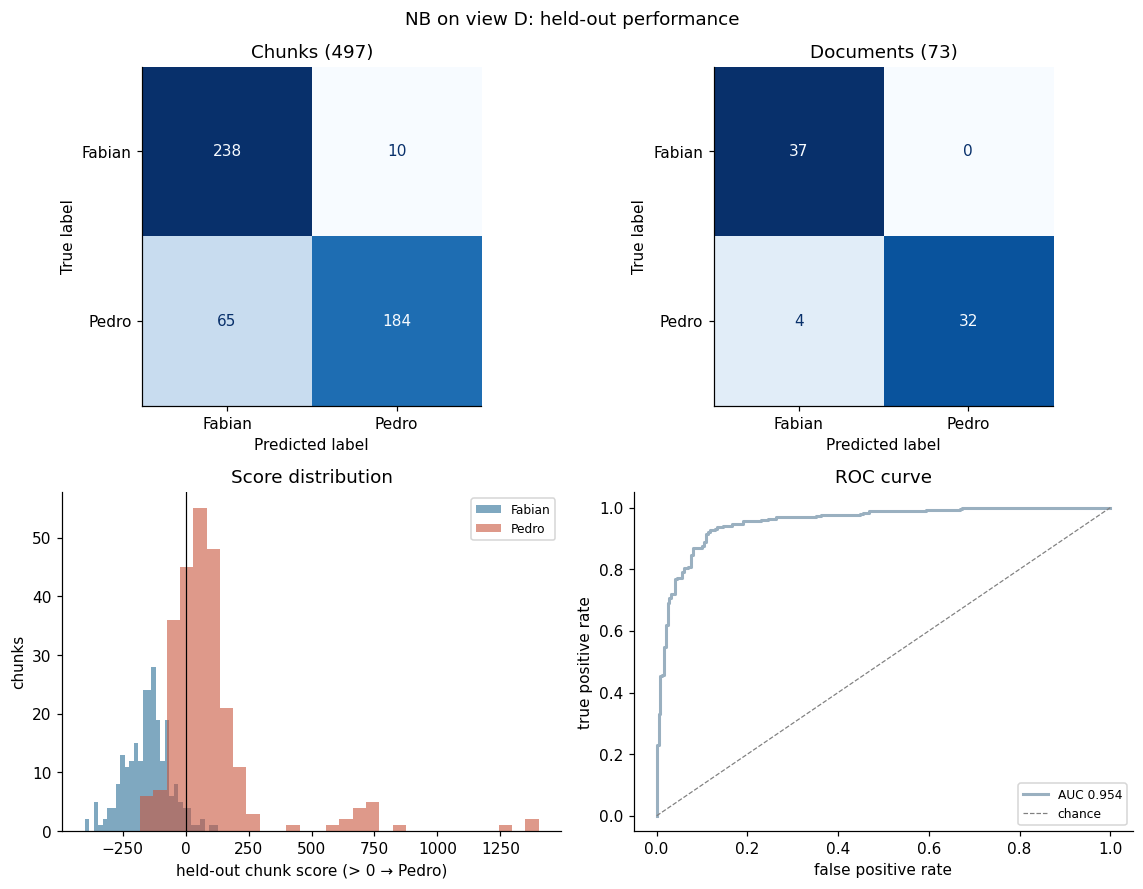

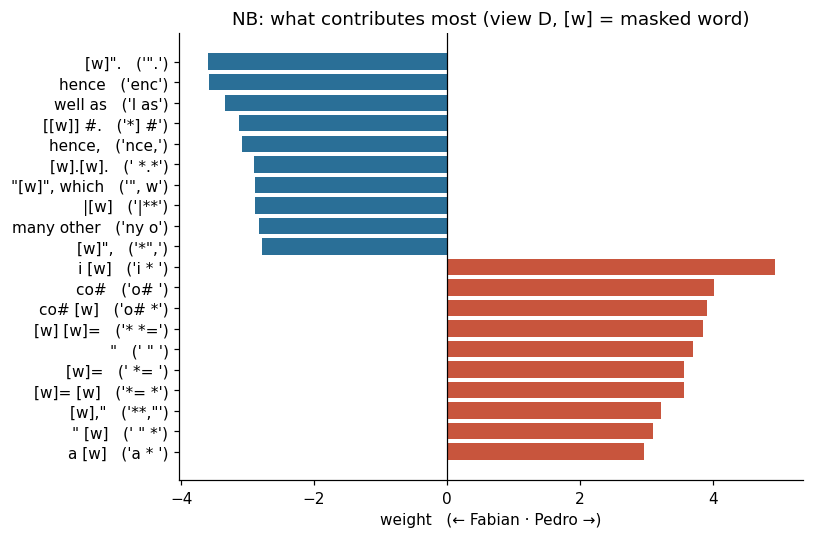

,n-gram,weight,Fabian,Pedro
context,,,,
"[w]"".",""".",-3.60,36,0
hence,enc,-3.58,108,2
well as,l as,-3.35,85,2
[[w]] #.,*] #,-3.13,22,0
"hence,","nce,",-3.08,43,1
[w].[w].,*.*,-2.90,54,2
"""[w]"", which",""", w",-2.88,17,0
|[w],|**,-2.88,17,0
many other,ny o,-2.82,16,0


In [12]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline


class NaiveBayes(MultinomialNB):
    # multinomial naive bayes with a decision_function like the other two models: the log-odds of pedro
    def decision_function(self, X):
        log_p = self.predict_log_proba(X)          # log p(fabian | x), log p(pedro | x)
        return log_p[:, 1] - log_p[:, 0]


def naive_bayes(view_params, alpha=1.0):
    # raw counts for the chosen view + multinomial naive bayes with pseudocount alpha
    return make_pipeline(CountVectorizer(**view_params), NaiveBayes(alpha=alpha))

MAKERS["NB"] = naive_bayes   # register the model, so make_model(view, "NB") builds it
show_model("NB")              # grouped cv on all four views, details and top features for view D

**Interpretation.**
* **Views.** Well above the 0.50 baseline in every view (0.83–0.85); distorted text (D) is best.
* **Confusion matrices.** The errors are lopsided: 65 of Pedro's chunks go to me, only 10 of mine to him (recall 0.739 for Pedro vs. 0.960 for me). This costs four of Pedro's documents (69 of 73 correct).
* **Score distribution and ROC.** The log-odds run into the hundreds: 99.4% of chunks get a probability below 0.01 or above 0.99, and many of Pedro's chunks sit just below zero. The AUC (0.954) is much better than the accuracy, so the *ranking* is good but the threshold of 0 is in the wrong place: summing thousands of correlated log-ratios inflates the scores.
* **What contributes most.** Each bar is an n-gram of view D, labelled with the words it most often comes from (`[w]` is a masked word). Because its weights are $\log(\theta_{d,\text{Pedro}}/\theta_{d,\text{Fabian}})$, Naive Bayes favours patterns one of us *almost never* uses, however rare: *hence* (108 vs. 2 uses) and *well as* (85 vs. 2) for me; inline equals signs (`[w]=`, 34–46 vs. 0) and `co#` for Pedro. `co#` is "CO2", a small topic leak, because scikit-learn's stop-word list contains "co". Many of these are formatting habits rather than prose style.
* **Probabilities.** Being so certain makes its mistakes expensive: log loss 4.24, sixteen times that of logistic regression.

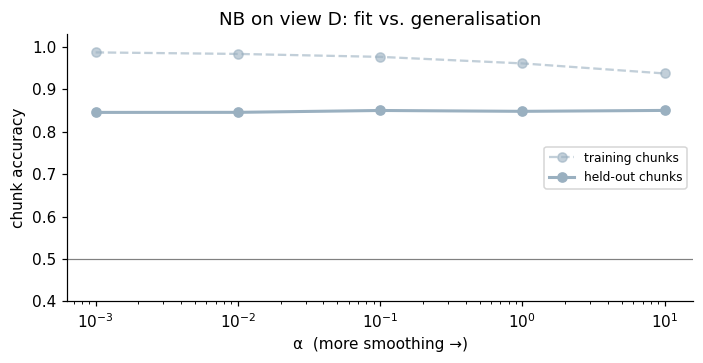

alpha,0.001,0.010,0.100,1.000,10.000
training,0.987,0.983,0.977,0.961,0.937
held-out,0.846,0.846,0.850,0.848,0.850


In [13]:
# how the smoothing pseudocount alpha changes training and held-out accuracy
nb_curve = hyper_curve("NB", "alpha", [0.001, 0.01, 0.1, 1, 10], "α  (more smoothing →)")

**How Naive Bayes learns.** More smoothing pulls both authors' distributions together, so training accuracy falls (0.987 at $\alpha=0.001$, 0.937 at $\alpha=10$), but held-out accuracy stays flat at 0.85. The error therefore likely comes from the model's *bias*, the independence assumption, which no value of $\alpha$ can fix. That motivates the next model.

### 5.2 Logistic regression (in class)

The Naive Bayes score is a weighted sum of features; passed through a sigmoid it has exactly the logistic form $p(y=1\mid\mathbf x)=\sigma(\mathbf w^\top\mathbf x+b)$ (Murphy, §9.3.4). The difference is how the weights are set. Naive Bayes derives each from one feature's counts; logistic regression is *discriminative* and fits all weights jointly, so if `" th"`, `"the"` and `"he "` carry the same evidence, it can split the weight among them.

**TF-IDF input (not covered in class).** Counts are reweighted so that terms frequent in every chunk do not dominate (Murphy, Eq. 1.38), and each row is scaled to unit length:

$$\text{TFIDF}_{dj} = \log(1+\text{TF}_{dj})\cdot\log\frac{N}{1+\text{DF}_d},\qquad \tilde{\mathbf x}_j=\frac{\mathbf x_j}{\lVert\mathbf x_j\rVert_2},$$

where $\text{TF}_{dj}$ counts term $d$ in chunk $j$ and $\text{DF}_d$ is the number of chunks containing it.

**Objective.** With $\mu_n=\sigma(\mathbf w^\top\mathbf x_n+b)$, the weights minimise the negative log-likelihood plus an L2 (Gaussian-prior) penalty (Murphy, Eqs. 10.6, 10.47); scikit-learn uses $C=1/(2\lambda)$, so a small $C$ is strong regularisation:

$$\mathcal L(\mathbf w)= -\sum_n\big[y_n\log\mu_n+(1-y_n)\log(1-\mu_n)\big] + \lambda\lVert\mathbf w\rVert_2^2 .$$

**Training.** The loss is convex (Murphy, Eqs. 10.23–10.25), so there is a single optimum (we are doing this in CS164 right now!). Its gradient (Eq. 10.21) is $\nabla_{\mathbf w}\mathcal L=\sum_n(\mu_n-y_n)\,\mathbf x_n+2\lambda\mathbf w$, so every chunk pulls on $\mathbf w$ in proportion to its error. scikit-learn's L-BFGS solver follows this gradient with a curvature estimate; the logic is gradient descent:
```
w ← 0, b ← 0
repeat until the loss stops decreasing:
    μ_n ← σ(wᵀx_n + b) for every training chunk
    w ← w − η [ Σ_n (μ_n − y_n) x_n + 2λ w ];   b ← b − η Σ_n (μ_n − y_n)
```
The chunk score is the logit $\mathbf w^\top\mathbf x+b$. I fixed $C=10$ before running anything; the regularisation curve below checks that choice.

view,chunk acc,precision,recall,F1,chunk AUC,doc acc,doc 95% CI
A content,0.887,0.929,0.839,0.882,0.960,0.945,"[0.89, 0.99]"
B function,0.877,0.879,0.876,0.877,0.954,1.000,"[1.00, 1.00]"
C char,0.926,0.973,0.876,0.922,0.989,1.000,"[1.00, 1.00]"
D distorted,0.946,0.951,0.940,0.945,0.984,1.000,"[1.00, 1.00]"


,value,what it measures
metric,,
majority baseline,0.501,always guess the larger class
accuracy,0.946,share of chunks attributed correctly
precision (Pedro),0.951,"when it says Pedro, how often it is right"
recall (Pedro),0.940,share of Pedro's chunks it finds
recall (Fabian),0.952,share of my chunks it finds
F1 (Pedro),0.945,harmonic mean of precision and recall
ROC-AUC,0.984,"ranking quality, independent of the threshold"
log loss,0.265,punishes confident mistakes (lower = better)
Brier score,0.070,squared error of the probabilities (lower = better)


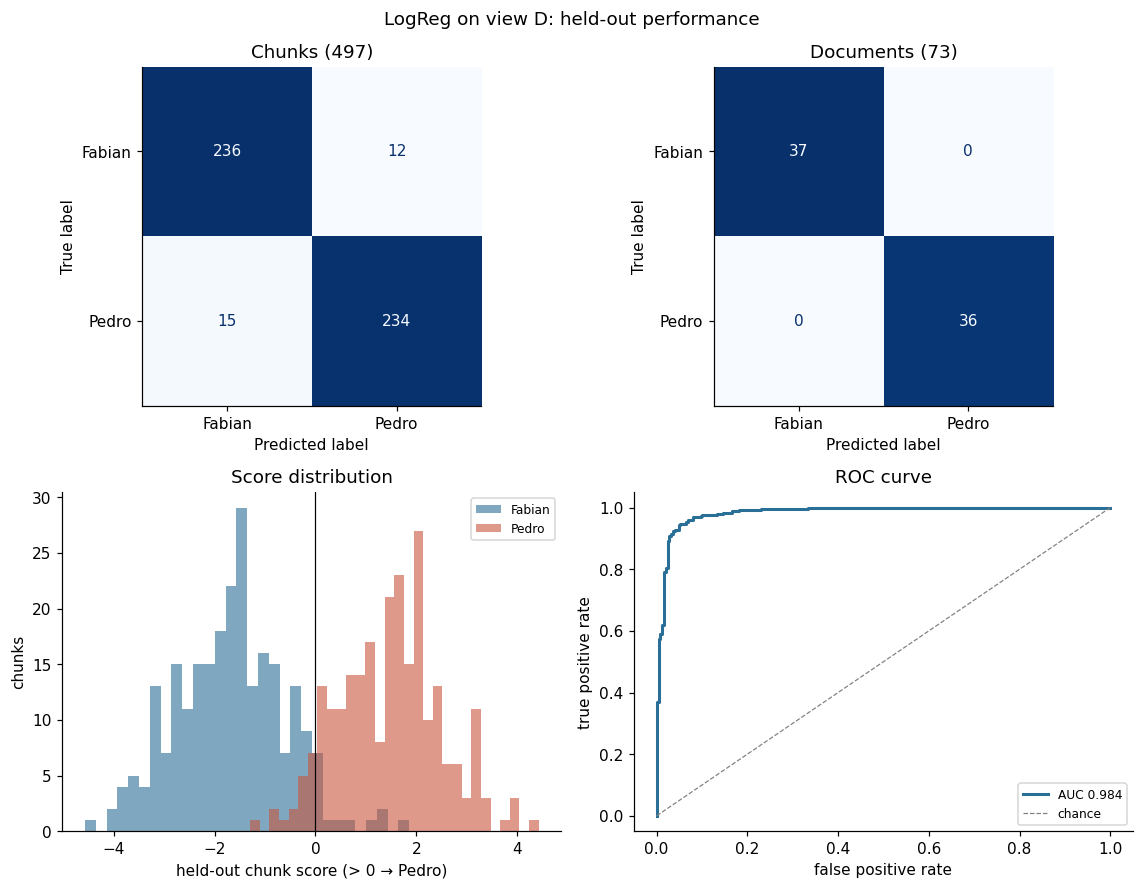

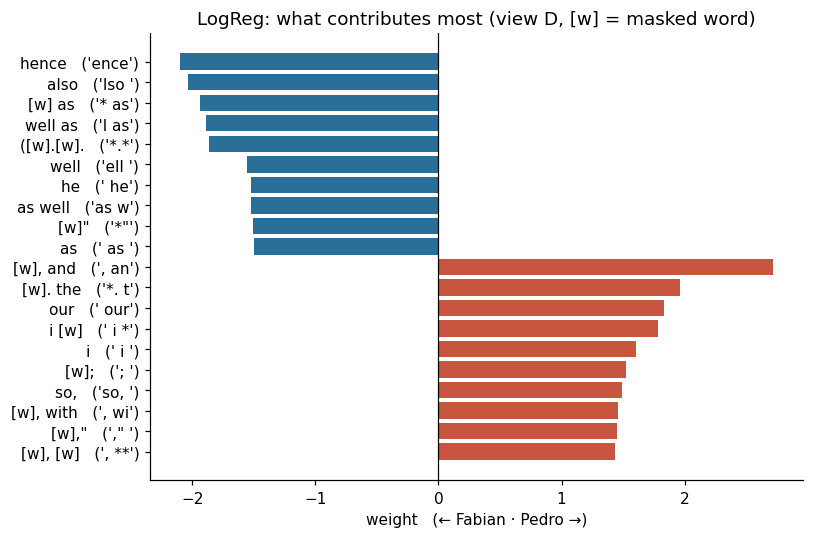

,n-gram,weight,Fabian,Pedro
context,,,,
hence,ence,-2.10,108,2
also,lso,-2.03,254,74
[w] as,* as,-1.94,477,200
well as,l as,-1.89,85,2
([w].[w].,*.*,-1.86,150,39
well,ell,-1.55,103,17
he,he,-1.52,192,76
as well,as w,-1.52,140,37
"[w]""","*""",-1.51,313,85


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def logistic_regression(view_params, C=10):
    # tf-idf features for the chosen view + l2-regularised logistic regression, C = 1 / (2 lambda)
    return make_pipeline(TfidfVectorizer(**view_params, sublinear_tf=True),   # sublinear: log(1 + tf)
                         LogisticRegression(C=C, max_iter=5000))

MAKERS["LogReg"] = logistic_regression   # register the model
show_model("LogReg")                      # grouped cv on all four views, details and top features for view D

**Interpretation.**
* **Views.** Better than Naive Bayes in every view, best on D, and every document right on views B, C and D.
* **Confusion matrices.** On view D, 470 of 497 chunks are right (0.946) and the errors are balanced (12 of mine, 15 of Pedro's; recall 0.952 vs. 0.940). Fitting the weights jointly removes Naive Bayes's lean towards me. All 73 documents and all 37 assignments are right.
* **Score distribution and ROC.** The logits are moderate (around ±2), and the misattributed chunks sit near zero, so its mistakes are uncertain ones. AUC 0.984, three points above Naive Bayes.
* **What contributes most.** Frequent habits instead of rare ones. Mine: *hence* (108 vs. 2 uses), *also* (254 vs. 74), *[w] as* (477 vs. 200), *as well*, and abbreviations like *e.g.* (`[w].[w].`, 150 vs. 39). Pedro's: *[w], and* (355 vs. 142), sentences starting with *the* (694 vs. 421), *I [w]* (670 vs. 215), *our*, semicolons and *so,*. These match the function-word fingerprint (8.1) and the punctuation statistics (8.2).
* **Probabilities.** Log loss 0.265 and Brier score 0.070: not overconfident, if anything too cautious (5.4).

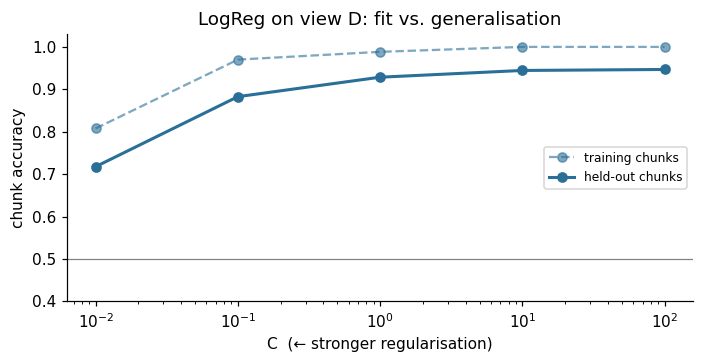

C,0.01,0.10,1.00,10.00,100.00
training,0.808,0.970,0.988,1.000,1.000
held-out,0.718,0.883,0.929,0.944,0.947


In [15]:
# how the regularisation strength C changes training and held-out accuracy
lr_curve = hyper_curve("LogReg", "C", [0.01, 0.1, 1, 10, 100], "C  (← stronger regularisation)")

**How logistic regression learns.** Strong regularisation underfits (0.81 training and 0.72 held-out accuracy at $C=0.01$). From $C=10$ the training chunks are fitted perfectly, since 450 chunks are linearly separable in ~8,000 n-gram dimensions. Yet held-out accuracy does not fall; it creeps up to 0.947 at $C=100$, because on separable data a weakly regularised logistic regression moves towards the maximum-margin boundary, much like an SVM. My pre-set $C=10$ is on the plateau. I did not tune it on this curve, which uses the evaluation folds.

### 5.3 Linear support vector machine (beyond class; Murphy, §17.3)

Many hyperplanes separate my training chunks from Pedro's. Logistic regression picks the one that makes the labels most probable; the SVM picks the one with the widest gap to the closest chunks. It uses the same TF-IDF input, scores a chunk by $f(\mathbf x)=\mathbf w^\top\mathbf x+b$, and labels Fabian $\tilde y=-1$, Pedro $\tilde y=+1$.

**Soft margin.** A point's distance from the boundary is $|f(\mathbf x)|/\lVert\mathbf w\rVert$ (Eq. 17.66). Scaling $\mathbf w$ so that the closest points have $\tilde y f(\mathbf x)=1$, the gap is $2/\lVert\mathbf w\rVert$, so maximising it means minimising $\lVert\mathbf w\rVert^2$. Real data overlap, so each point gets a slack $\xi_n\ge0$, charged at rate $C$ (Eqs. 17.68, 17.83):

$$\min_{\mathbf w,b,\boldsymbol\xi}\;\tfrac12\lVert\mathbf w\rVert^2 + C\sum_{n=1}^{N}\xi_n
\quad\text{s.t.}\quad \tilde y_n(\mathbf w^\top\mathbf x_n+b)\ge 1-\xi_n,\;\;\xi_n\ge 0 .$$

A large $C$ insists on separating every training chunk (narrow margin, risk of overfitting); a small $C$ accepts some mistakes for a wider margin.

**Hinge loss.** At the optimum $\xi_n=\max(0,\,1-\tilde y_n f(\mathbf x_n))$, which turns the problem into an unconstrained loss with the same shape as logistic regression's; only the loss changes (§17.3.6):

$$\mathcal L(\mathbf w)=\sum_{n}\underbrace{\max\big(0,\;1-\tilde y_n f(\mathbf x_n)\big)}_{\text{hinge loss}}+\lambda\lVert\mathbf w\rVert^2,\qquad\lambda=\frac{1}{2C}.$$

The figure below plots both losses against the margin $m=\tilde y f(\mathbf x)$. The logistic loss is never zero, so every chunk keeps pulling on $\mathbf w$; the hinge loss is zero once $m\ge1$, so only the chunks on or inside the margin, the **support vectors**, shape the solution (Eq. 17.63).

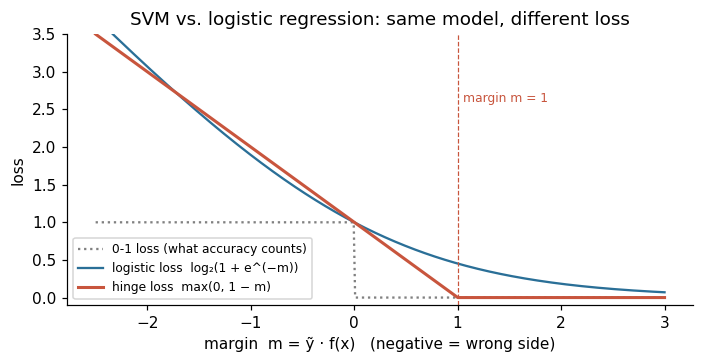

In [16]:
# plotting the three losses as a function of the margin m = y * f(x)
m = np.linspace(-2.5, 3, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(m, (m < 0).astype(float), color="grey", ls=":", label="0-1 loss (what accuracy counts)")
ax.plot(m, np.log2(1 + np.exp(-m)), color=MODEL_COLORS["LogReg"], label="logistic loss  log₂(1 + e^(−m))")
ax.plot(m, np.maximum(0, 1 - m), color="#c8553d", lw=2, label="hinge loss  max(0, 1 − m)")
ax.axvline(1, color="#c8553d", lw=0.8, ls="--"); ax.text(1.05, 2.6, "margin m = 1", color="#c8553d", fontsize=8)
ax.set_xlabel("margin  m = ỹ · f(x)   (negative = wrong side)"); ax.set_ylabel("loss"); ax.set_ylim(-0.1, 3.5)
ax.legend(fontsize=8); ax.set_title("SVM vs. logistic regression: same model, different loss")
plt.tight_layout(); plt.savefig(FIG / "losses.png", bbox_inches="tight"); plt.show()

**Training.** `LinearSVC` uses dual coordinate descent; the logic is easiest to see as subgradient descent on the hinge loss:
```
w ← 0, b ← 0
repeat for T epochs, for each training chunk (x_n, ỹ_n) in random order:
    if ỹ_n (wᵀx_n + b) < 1:            # inside the margin or misclassified: hinge is active
        w ← w − η (2λ w − ỹ_n x_n);   b ← b + η ỹ_n
    else:                              # safely classified: only the regulariser acts
        w ← w − η (2λ w)
```
The chunk score is the signed margin $f(\mathbf x)$. I fixed $C=0.5$ before running anything.

view,chunk acc,precision,recall,F1,chunk AUC,doc acc,doc 95% CI
A content,0.879,0.957,0.795,0.868,0.957,0.932,"[0.86, 0.99]"
B function,0.871,0.871,0.871,0.871,0.942,0.986,"[0.96, 1.00]"
C char,0.895,0.985,0.803,0.885,0.985,0.973,"[0.93, 1.00]"
D distorted,0.936,0.947,0.924,0.935,0.983,1.000,"[1.00, 1.00]"


,value,what it measures
metric,,
majority baseline,0.501,always guess the larger class
accuracy,0.936,share of chunks attributed correctly
precision (Pedro),0.947,"when it says Pedro, how often it is right"
recall (Pedro),0.924,share of Pedro's chunks it finds
recall (Fabian),0.948,share of my chunks it finds
F1 (Pedro),0.935,harmonic mean of precision and recall
ROC-AUC,0.983,"ranking quality, independent of the threshold"
log loss,"n/a (margin, not a probability)",punishes confident mistakes (lower = better)
Brier score,"n/a (margin, not a probability)",squared error of the probabilities (lower = better)


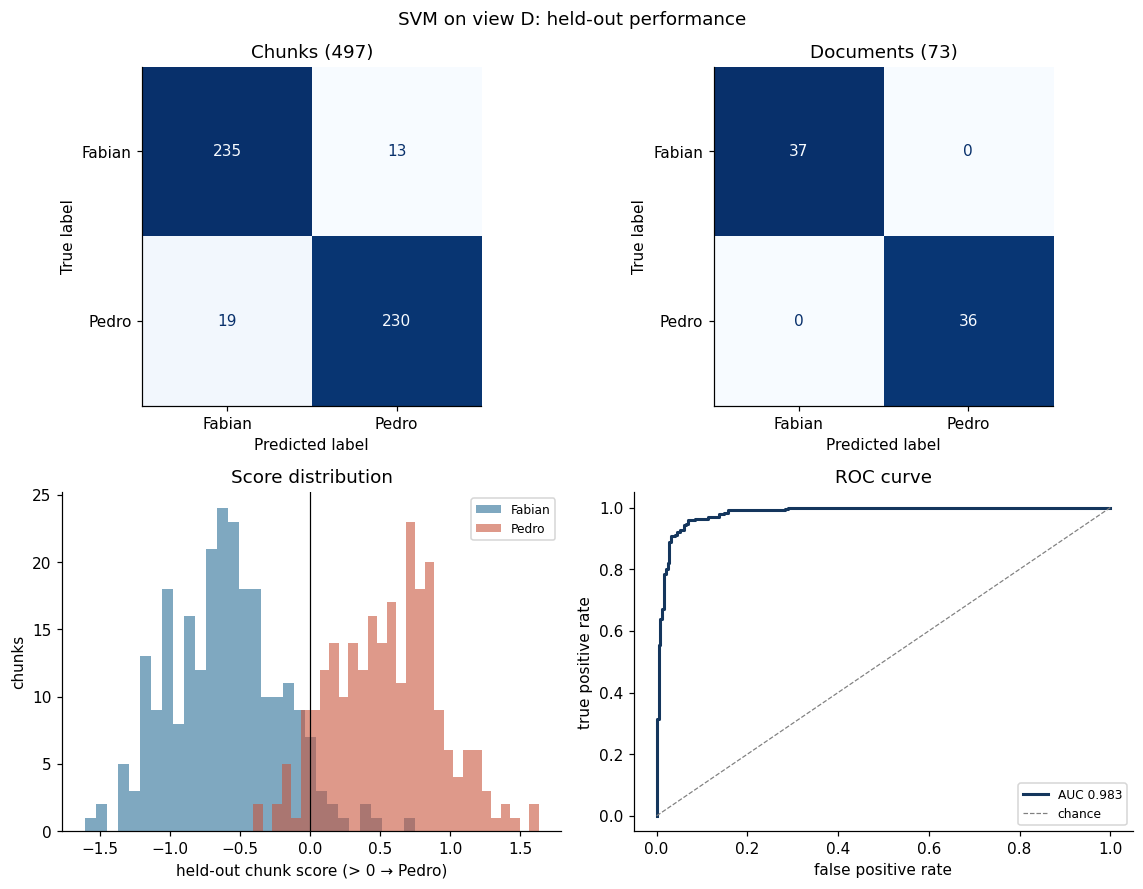

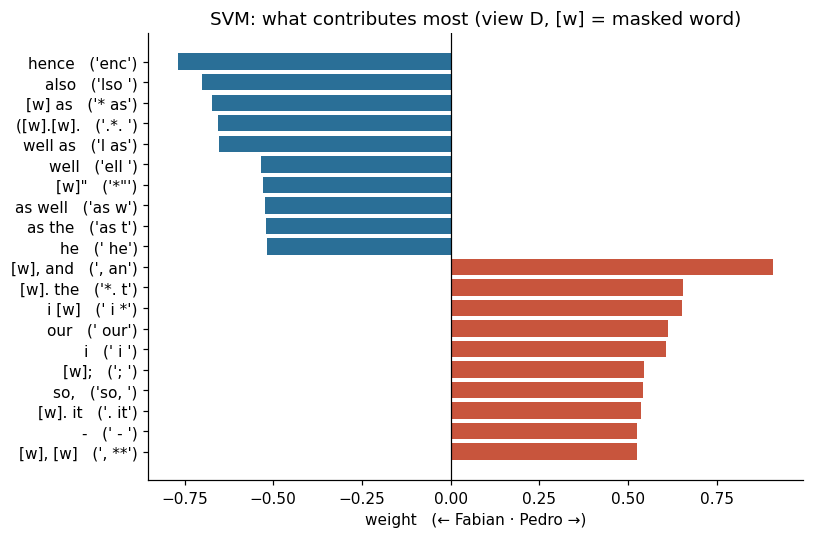

,n-gram,weight,Fabian,Pedro
context,,,,
hence,enc,-0.77,108,2
also,lso,-0.70,254,74
[w] as,* as,-0.67,477,200
([w].[w].,.*.,-0.65,94,6
well as,l as,-0.65,85,2
well,ell,-0.53,103,17
"[w]""","*""",-0.53,313,85
as well,as w,-0.52,140,37
as the,as t,-0.52,271,139


In [17]:
from sklearn.svm import LinearSVC

def linear_svm(view_params, C=0.5):
    # tf-idf features + soft-margin linear svm; loss="hinge" because scikit-learn's default is the squared hinge
    return make_pipeline(TfidfVectorizer(**view_params, sublinear_tf=True),
                         LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000))

MAKERS["SVM"] = linear_svm   # register the model
show_model("SVM")             # grouped cv on all four views, details and top features for view D

**Interpretation.**
* **Views.** Within one point of logistic regression on views B and D; on raw character n-grams (C) it falls behind (0.895 vs. 0.926).
* **Confusion matrices.** On view D, 0.936 of chunks are right with balanced errors (recall 0.924 for Pedro, 0.948 for me), and all 73 documents are right.
* **Score distribution and ROC.** AUC 0.983: it ranks the chunks almost exactly like logistic regression.
* **What contributes most.** Almost the same habits as logistic regression (*hence, also, as*, abbreviations; *[w], and*, *the*, *I*, *our*, semicolons), plus dashes for Pedro (201 vs. 85 uses). Relying on the same habits is why the two models agree on every document.
* **Probabilities.** None: the SVM outputs a distance to the boundary, one practical reason to prefer logistic regression as the final model.

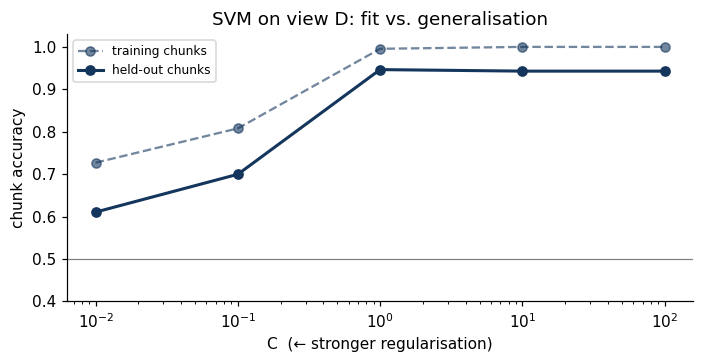

C,0.01,0.10,1.00,10.00,100.00
training,0.727,0.808,0.996,1.000,1.000
held-out,0.611,0.700,0.946,0.943,0.943


In [18]:
# how the penalty C on margin violations changes training and held-out accuracy
svm_curve = hyper_curve("SVM", "C", [0.01, 0.1, 1, 10, 100], "C  (← stronger regularisation)")

**How the SVM learns.** The same shape as logistic regression, but a much steeper cliff: at $C\le0.1$ the SVM underfits badly (0.61 and 0.70 held-out, against 0.72 and 0.88), because margin violations are cheap and it prefers a tiny $\mathbf w$. From $C=1$ held-out accuracy plateaus at 0.94–0.95. My pre-set $C=0.5$ sits just below the plateau, which explains most of its one-point gap to logistic regression.

### 5.4 The three models side by side

| | Naive Bayes | Logistic regression | Linear SVM |
|---|---|---|---|
| Type | generative: models how each author *produces* text, $p(\mathbf x\mid y)$ | discriminative: models $p(y\mid\mathbf x)$ directly | discriminative, not probabilistic: finds the widest margin |
| Input | raw counts | TF-IDF | TF-IDF |
| How weights are set | counted from feature frequencies, closed form | minimising log-loss + L2 penalty | minimising hinge loss + L2 penalty |
| Key assumption | features independent given the author | none about the features | none about the features |
| Chunk score | log-odds | logit | signed margin |
| Hyperparameter | pseudocount $\alpha=1$ | $C=10$ | $C=0.5$ |

model,chunk acc,precision,recall,F1,chunk AUC,doc acc,doc 95% CI
NB,0.849,0.948,0.739,0.831,0.954,0.945,"[0.89, 0.99]"
LogReg,0.946,0.951,0.940,0.945,0.984,1.000,"[1.00, 1.00]"
SVM,0.936,0.947,0.924,0.935,0.983,1.000,"[1.00, 1.00]"


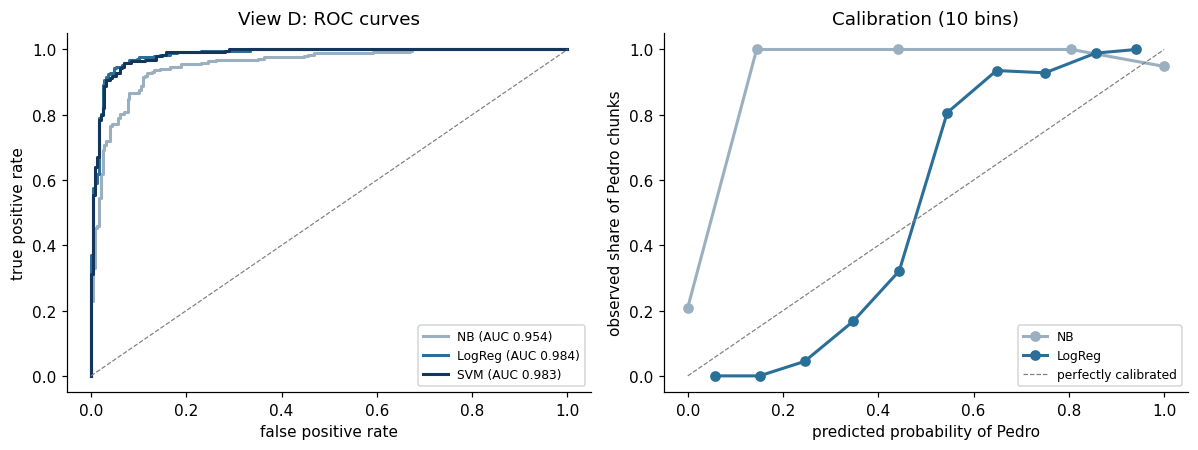

,log loss,Brier score,chunks with p < 0.01 or > 0.99
model,,,
NB,4.237,0.149,0.994
LogReg,0.265,0.070,0.000


In [19]:
from sklearn.calibration import calibration_curve

# the three models on view D, from the held-out scores computed in 5.1-5.3
display(pd.DataFrame([RESULTS[("D distorted", name)] for name in ["NB", "LogReg", "SVM"]]).drop(columns="view")
        .style.format(precision=3).hide(axis="index"))

# plotting the three roc curves on top of each other, and calibration of the two probabilistic models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name in ["NB", "LogReg", "SVM"]:
    s = OOF[("D distorted", name)][0]
    fpr, tpr, _ = roc_curve(chunks.y, s)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"{name} (AUC {roc_auc_score(chunks.y, s):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--"); axes[0].legend(fontsize=8)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("View D: ROC curves")
calibration_rows = []
for name in ["NB", "LogReg"]:
    p = expit(OOF[("D distorted", name)][0])                                   # predicted probability of pedro
    true_share, mean_pred = calibration_curve(chunks.y, p, n_bins=10)        # observed share of pedro per bin
    axes[1].plot(mean_pred, true_share, marker="o", color=MODEL_COLORS[name], lw=2, label=name)
    calibration_rows.append({"model": name, "log loss": log_loss(chunks.y, p), "Brier score": brier_score_loss(chunks.y, p),
                             "chunks with p < 0.01 or > 0.99": np.mean((p < 0.01) | (p > 0.99))})
axes[1].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--", label="perfectly calibrated"); axes[1].legend(fontsize=8)
axes[1].set_xlabel("predicted probability of Pedro"); axes[1].set_ylabel("observed share of Pedro chunks")
axes[1].set_title("Calibration (10 bins)")
plt.tight_layout(); plt.savefig(FIG / "roc_calibration.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(calibration_rows).set_index("model").round(3))

Logistic regression and the SVM are tied (0.946 vs. 0.936 chunk accuracy, AUC 0.984 vs. 0.983, both 73/73 documents) and 9–10 points ahead of Naive Bayes: changing the loss hardly matters, while the independence assumption costs a lot.

The **calibration curves** show the two probabilistic models failing in opposite directions. Naive Bayes is wildly overconfident (99.4% of chunks get a probability below 0.01 or above 0.99), so its curve is essentially a jump from 0 to 1. Logistic regression is *under*confident: chunks it gives a 25% chance of being Pedro's are his only about 5% of the time, and those at 65% about 93%. The L2 penalty and the unit-length TF-IDF rows keep its logits small, which pulls its probabilities towards 0.5. Its ranking and threshold are right, so accuracy is unaffected, but its probabilities should not be read literally.

## 6. How the models learn, compared

Two questions need all three models side by side: **(a)** how much training data they need, and **(b)** how much text they need at test time. Both use view D and the grouped CV.

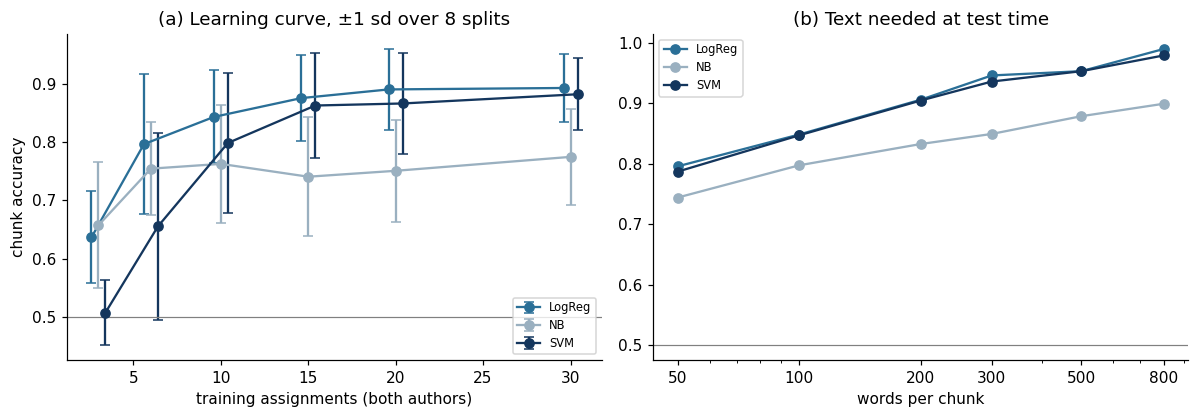

model,LogReg,NB,SVM
assignments,,,
3,0.637,0.657,0.507
6,0.797,0.754,0.655
10,0.843,0.763,0.799
15,0.876,0.741,0.863
20,0.891,0.751,0.866
30,0.893,0.775,0.882


model,LogReg,NB,SVM
words,,,
50,0.796,0.744,0.787
100,0.848,0.797,0.847
200,0.906,0.832,0.904
300,0.946,0.849,0.936
500,0.953,0.878,0.953
800,0.989,0.899,0.979


In [20]:
# (a) learning curve: number of training assignments (7 held-out assignments, 8 random splits)
curve_rows = []
for rep in range(8):
    perm = RNG.permutation(docs.assignment.unique())                        # shuffle the 37 assignments
    test, pool = chunks[chunks.assignment.isin(perm[:7])], perm[7:]         # 7 for testing, 30 to train from
    for k in [3, 6, 10, 15, 20, 30]:
        train = chunks[chunks.assignment.isin(pool[:k])]                    # first k training assignments
        for name in ["NB", "LogReg", "SVM"]:
            fitted = make_model("D distorted", name).fit(train.text, train.y)
            curve_rows.append({"model": name, "assignments": k, "acc": fitted.score(test.text, test.y)})
data_curve = pd.DataFrame(curve_rows)

# (b) accuracy vs. chunk length
length_rows = []
for size in [50, 100, 200, 300, 500, 800]:
    data = make_chunks(docs, size)                                          # re-chunk the documents
    for name in ["NB", "LogReg", "SVM"]:
        s = cv_scores(make_model("D distorted", name), data)                # grouped cv as everywhere else
        length_rows.append({"model": name, "words": size, "acc": accuracy_score(data.y, s > 0)})
length_curve = pd.DataFrame(length_rows)

# plotting the three curves
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for offset, (name, g) in zip([-0.4, 0, 0.4], data_curve.groupby("model")):
    s = g.groupby("assignments").acc.agg(["mean", "std"])
    axes[0].errorbar(s.index + offset, s["mean"], yerr=s["std"], marker="o", capsize=3, color=MODEL_COLORS[name], label=name)
axes[0].set_xlabel("training assignments (both authors)"); axes[0].set_ylabel("chunk accuracy")
axes[0].set_title("(a) Learning curve, ±1 sd over 8 splits"); axes[0].legend(fontsize=7.5)
for name, g in length_curve.groupby("model"):
    axes[1].plot(g.words, g.acc, marker="o", color=MODEL_COLORS[name], label=name)
axes[1].set_xscale("log"); axes[1].set_xticks([50, 100, 200, 300, 500, 800], [50, 100, 200, 300, 500, 800])
axes[1].set_xlabel("words per chunk"); axes[1].set_title("(b) Text needed at test time"); axes[1].legend(fontsize=7.5)
for ax in axes:
    ax.axhline(0.5, color="grey", lw=0.8)
plt.tight_layout(); plt.savefig(FIG / "learning.png", bbox_inches="tight"); plt.show()
display(data_curve.pivot_table(index="assignments", columns="model", values="acc").round(3))   # (a) mean over 8 splits
display(length_curve.pivot(index="words", columns="model", values="acc").round(3))             # (b)

**(a) Training data.** With 3 training assignments Naive Bayes is slightly ahead (0.66 vs. 0.64), and the SVM is at chance (0.51). From 6 assignments on, logistic regression leads (0.80 vs. 0.75), and the SVM catches up at about 15. Generative Naive Bayes reaches its lower ceiling early (0.75–0.78), while the discriminative models are still rising at 30 assignments (0.89 and 0.88), so more data would likely still help them (a potential step for the next assignment). The SVM needs the most data because with few chunks its boundary rests on a handful of support vectors.

**(b) Text at test time.** The discriminative models reach about 0.79 with 50 words, 0.90 at 200 and 0.98–0.99 at 800. Naive Bayes goes from 0.74 to 0.90, and its gap to the others *widens* with length: longer chunks contain more overlapping n-grams, which the independence assumption double-counts.

## 8. Final model performance

The final model is **logistic regression on distorted text (view D)**. It ties with the SVM for the best held-out accuracy, never sees a content word, has interpretable weights and probabilities, learns from less data (Section 6a) and is less sensitive to its hyperparameter (5.2–5.3). Its held-out performance is in Section 5.2: 470 of 497 chunks (0.946, F1 0.945, AUC 0.984), all 73 documents and all 37 assignments, with an exact 95% interval of [0.905, 1.00] when assignments are the unit. This section looks at what it learned.

### 8.1 Function-word fingerprint

To read the habits in plain words, I fit the same logistic regression on the function-word view (B) on all chunks and show its largest weights next to the raw rates per 1,000 words.

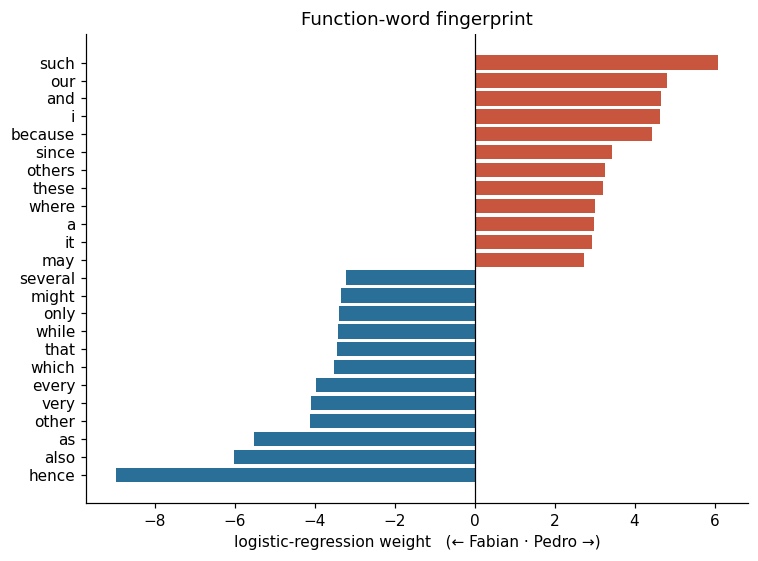

,hence,also,as,other,very,every,which,that,while,only,...,a,where,these,others,since,because,i,and,our,such
author,,,,,,,,,,,,,,,,,,,,,
Fabian,1.48,3.61,12.12,1.40,1.29,0.77,5.80,13.06,2.00,1.83,...,21.29,0.72,1.52,0.15,0.12,0.59,5.62,22.18,1.15,0.40
Pedro,0.03,1.35,6.35,0.57,0.52,0.24,3.21,9.59,1.08,0.69,...,22.48,1.41,2.36,0.45,0.60,1.45,12.39,26.72,2.92,1.19
ratio,0.02,0.37,0.52,0.41,0.40,0.31,0.55,0.73,0.54,0.38,...,1.06,1.96,1.55,3.00,5.00,2.46,2.20,1.20,2.54,2.97


In [21]:
# fit on all chunks: this is descriptive (which words separate us), not an evaluation
fw_model = make_model("B function", "LogReg").fit(chunks.text, chunks.y)
vocab = np.array(fw_model[0].get_feature_names_out())    # the function words
w = fw_model[-1].coef_[0]                                 # one weight per function word (+ = pedro)
top = np.r_[np.argsort(w)[:12], np.argsort(w)[-12:]]      # 12 most fabian-like and 12 most pedro-like words

# raw usage rates per 1,000 words, to check the weights against something interpretable
counts = pd.DataFrame(CountVectorizer(token_pattern=WORD, vocabulary=FUNCTION_WORDS).transform(docs.text).toarray(),
                      columns=FUNCTION_WORDS).assign(author=docs.author.values)
rates = counts.groupby("author").sum().T / docs.groupby("author").words.sum() * 1000

# plotting the weights
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(vocab[top], w[top], color=[COLORS["Fabian"] if x < 0 else COLORS["Pedro"] for x in w[top]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("logistic-regression weight   (← Fabian · Pedro →)"); ax.set_title("Function-word fingerprint")
plt.tight_layout(); plt.savefig(FIG / "fingerprint.png", bbox_inches="tight"); plt.show()
display(rates.loc[vocab[top]].round(2).assign(ratio=lambda r: (r.Pedro / r.Fabian).round(2)).T)

### 8.2 Punctuation and sentence habits

Twelve interpretable style statistics per document, compared across the 37 assignments with a **paired Wilcoxon signed-rank test** (Wilcoxon, 1945; not covered in class). With $d_i$ Pedro's value minus mine on assignment $i$ and $R_i$ the rank of $|d_i|$,

$$W=\sum_{i=1}^{37}\operatorname{sign}(d_i)\,R_i ,$$

which is centred on zero if neither of us uses the feature more; unlike a t-test, it does not assume normal differences. Because 12 tests produce some small p-values by chance, the table also reports **Holm-adjusted** p-values (Holm, 1979): sort the p-values, multiply the $i$-th smallest by $12-i+1$, and take the running maximum.

In [22]:
def style_stats(text):
    # interpretable style statistics for one document
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) > 2]   # sentences of 3+ words
    lengths = np.array([len(s.split()) for s in sentences])                           # words per sentence
    words = re.findall(WORD, text.lower())
    per_k = lambda pattern: 1000 * len(re.findall(pattern, text)) / max(len(words), 1)  # occurrences per 1,000 words
    return pd.Series({
        "mean sentence length": lengths.mean(), "sentence length sd": lengths.std(),
        "type-token ratio (first 500 words)": len(set(words[:500])) / max(len(words[:500]), 1),  # vocabulary richness
        "mean word length": np.mean([len(x) for x in words]),
        "commas /1k words": per_k(r","), "semicolons /1k": per_k(r";"), "colons /1k": per_k(r":"),
        "parentheses /1k": per_k(r"\("), "dashes /1k": per_k(r" - "), "questions /1k": per_k(r"\?"),
        "first person 'I' /1k": per_k(r"\bI\b"), "'we' /1k": per_k(r"\b[Ww]e\b")})

st = docs.text.apply(style_stats).assign(author=docs.author, assignment=docs.assignment)  # one row per document
paired = st.pivot(index="assignment", columns="author")       # my value and pedro's value side by side
rows = []
for col in st.columns.drop(["author", "assignment"]):
    f, p = paired[(col, "Fabian")], paired[(col, "Pedro")]
    rows.append({"statistic": col, "Fabian (median)": f.median(), "Pedro (median)": p.median(),
                 "Pedro higher in": f"{(p > f).sum()}/37", "Wilcoxon p": stats.wilcoxon(f, p).pvalue})  # paired test
tests = pd.DataFrame(rows).set_index("statistic")
ranked = tests["Wilcoxon p"].sort_values()                                  # smallest p first
tests["Holm p"] = (ranked * np.arange(len(ranked), 0, -1)).cummax().clip(upper=1)  # holm: times 12, 11, ..., kept monotone
display(tests.style.format("{:.3f}", subset=["Fabian (median)", "Pedro (median)"])
        .format("{:.1g}", subset=["Wilcoxon p", "Holm p"]))

,Fabian (median),Pedro (median),Pedro higher in,Wilcoxon p,Holm p
statistic,,,,,
mean sentence length,25.931,23.464,11/37,0.0003,0.002
sentence length sd,14.672,11.481,12/37,0.02,0.1
type-token ratio (first 500 words),0.502,0.494,18/37,0.8,1
mean word length,5.059,5.145,23/37,0.1,0.6
commas /1k words,46.553,60.716,31/37,8e-06,0.0001
semicolons /1k,0.000,0.665,24/37,6e-05,0.0007
colons /1k,8.140,8.591,18/37,0.8,1
parentheses /1k,6.965,6.173,18/37,0.8,1
dashes /1k,0.634,2.905,26/37,0.0006,0.005


The fingerprint is clear, and reading it was the most fun part of the project:

* **"hence" is practically mine alone** (1.48 vs. 0.03 uses per 1,000 words), and I use *also, as, which, every, very, other, only* far more. My sentences link clauses and are longer (median 26 vs. 23 words).
* **Pedro uses "I" about twice as often** (12.4 vs. 5.6; more in 27 of 37 paired assignments), plus *our, because, since, such, these*: his reasoning is more explicitly causal and personal.
* **Punctuation:** Pedro uses more commas (61 vs. 47 per 1,000 words; more in 31 of 37 pairs), semicolons (my median is zero) and dashes. Vocabulary richness, word length, colons and parentheses do not differ.

After Holm correction, sentence length, commas, semicolons, dashes and "I" remain significant (adjusted p ≤ 0.005); the spread of sentence lengths and question marks do not.

### 8.3 How deep is the difference? Unmasking

If a few features carry the separation, removing them should make the two of us indistinguishable; if it is spread over many, accuracy should degrade slowly. Unmasking (Koppel & Schler, 2004) measures this. To keep the estimate held-out, features are removed using each fold's training chunks only:
```
for each grouped fold k = 1..10:
    features ← the 250 most frequent words (or 1,000 distorted n-grams) in train_k
    for round = 0..14:
        fit a linear SVM on train_k with the remaining features
        record which chunks of test_k it attributes correctly
        remove the 3 most negative (most Fabian-like) and 3 most positive (most Pedro-like) features of this SVM
acc[round] ← share of all held-out chunks attributed correctly in that round
```
The removed-feature lists printed below come from one extra run on all chunks and only show *which* features go first.

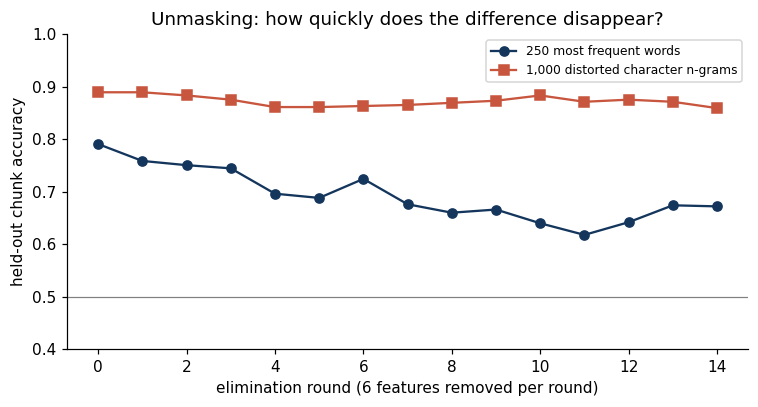

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
words,0.79,0.76,0.75,0.74,0.70,0.69,0.72,0.68,0.66,0.67,0.64,0.62,0.64,0.67,0.67
distorted n-grams,0.89,0.89,0.88,0.88,0.86,0.86,0.86,0.87,0.87,0.87,0.88,0.87,0.88,0.87,0.86


Words removed first (descriptive, fitted on all chunks):
  round 0: 'hence' | 'also' | 'every' | 'a' | 'our' | 'and'
  round 1: 'as' | 'only' | 'posterior' | 'right' | 'such' | 'algorithm'
  round 2: 'which' | 'other' | 'an' | 'multiple' | 'ratings' | 'because'
  round 3: 'of' | 'leads' | 'g' | 'team' | 'books' | 'i'
  round 4: 'that' | 'value' | 'class' | 'within' | 'impact' | 'food'
Distorted n-grams removed first (descriptive, fitted on all chunks):


  round 0: ' he' | 'as *' | '. f' | '. t' | '. it' | '. th'
  round 1: '? ' | '* wa' | '*.*' | '* it' | ', as' | '*. t'
  round 2: '.*' | 'ever' | 'l ' | ', i ' | '***.' | '**. '
  round 3: ' *.' | 'at t' | 'm th' | 'i **' | '*. ' | '**.'
  round 4: '# a' | 'her ' | 't th' | '*.' | 'om *' | ', wh'


In [23]:
from sklearn.preprocessing import StandardScaler

def unmask(vectorizer, rounds=15, remove=3):
    # unmasking inside grouped cv: features are ranked and removed using each fold's training chunks only
    correct = np.zeros((rounds, len(chunks)))                                # 1 = chunk attributed correctly in that round
    for train, test in GroupKFold(10).split(chunks.text, chunks.y, chunks.assignment):
        vec = clone(vectorizer).fit(chunks.text.iloc[train])                  # vocabulary from training chunks only
        X_train = vec.transform(chunks.text.iloc[train]).toarray()
        X_test = vec.transform(chunks.text.iloc[test]).toarray()
        y_train, y_test = chunks.y.iloc[train].values, chunks.y.iloc[test].values
        keep = np.arange(X_train.shape[1])                                    # features still in play in this fold
        for r in range(rounds):
            model = make_pipeline(StandardScaler(), LinearSVC(C=0.1, loss="hinge", dual=True, max_iter=20000))
            model.fit(X_train[:, keep], y_train)                              # fit on the training chunks only
            correct[r, test] = model.predict(X_test[:, keep]) == y_test       # held-out result this round
            w = model[-1].coef_[0]                                            # weights from the training chunks
            drop = np.r_[np.argsort(w)[:remove], np.argsort(w)[-remove:]]     # 3 most fabian-like + 3 most pedro-like
            keep = np.delete(keep, drop)                                      # removed for the next round
    return correct.mean(1)                                                    # held-out accuracy per round


def first_removed(vectorizer, rounds=5, remove=3):
    # descriptive only: which features go first when unmasking on all chunks (no accuracy is computed from this)
    X = vectorizer.fit_transform(chunks.text).toarray()
    names, keep, removed = vectorizer.get_feature_names_out(), np.arange(X.shape[1]), []
    for _ in range(rounds):
        w = make_pipeline(StandardScaler(), LinearSVC(C=0.1, loss="hinge", dual=True, max_iter=20000)).fit(
            X[:, keep], chunks.y)[-1].coef_[0]
        drop = np.r_[np.argsort(w)[:remove], np.argsort(w)[-remove:]]
        removed.append(" | ".join(repr(n) for n in names[keep[drop]]))
        keep = np.delete(keep, drop)
    return removed


word_vec = TfidfVectorizer(token_pattern=WORD, max_features=250, use_idf=False, norm="l1")       # word frequencies
char_vec = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), preprocessor=distort, max_features=1000,
                           use_idf=False, norm="l1")                                             # distorted n-grams
word_curve, char_curve = unmask(word_vec), unmask(char_vec)

# plotting both curves
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(word_curve, marker="o", color="#14365d", label="250 most frequent words")
ax.plot(char_curve, marker="s", color="#c8553d", label="1,000 distorted character n-grams")
ax.axhline(0.5, color="grey", lw=0.8); ax.set_ylim(0.4, 1)
ax.set_xlabel("elimination round (6 features removed per round)"); ax.set_ylabel("held-out chunk accuracy")
ax.set_title("Unmasking: how quickly does the difference disappear?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "unmasking.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame({"words": word_curve, "distorted n-grams": char_curve}).T.round(2))   # accuracy per round
for label, vec in [("Words", word_vec), ("Distorted n-grams", char_vec)]:
    print(f"{label} removed first (descriptive, fitted on all chunks):")
    for i, r in enumerate(first_removed(clone(vec))):
        print(f"  round {i}: {r}")

The word model starts at 0.79 and loses 9 points in four rounds (24 of 250 words gone), starting with the fingerprint words from 8.1 (*hence, also, every, our*), then levels off at 0.62–0.67. The distorted model starts at 0.89 and is still at 0.86 after 15 rounds: once its first casualties (sentence openings like `". th"`, my "as \*") are gone, the difference is spread over so many small punctuation and syntax patterns that removing the strongest hardly matters. That is why view D is the most robust. An earlier version ranked features on all chunks, including the held-out ones, and its word curve fell to chance; with the selection inside each fold, our difference turns out to be less concentrated in a few words.

## 9. Comparison conditions

All twelve combinations of model and view, under the same grouped CV.

### Four views × three models

view,model,chunk acc,precision,recall,F1,chunk AUC,doc acc,doc 95% CI
A content,NB,0.837,0.924,0.735,0.819,0.914,0.904,"[0.84, 0.96]"
B function,NB,0.847,0.871,0.815,0.842,0.925,0.918,"[0.85, 0.97]"
C char,NB,0.829,0.971,0.679,0.799,0.956,0.918,"[0.85, 0.97]"
D distorted,NB,0.849,0.948,0.739,0.831,0.954,0.945,"[0.89, 0.99]"
A content,LogReg,0.887,0.929,0.839,0.882,0.960,0.945,"[0.89, 0.99]"
B function,LogReg,0.877,0.879,0.876,0.877,0.954,1.000,"[1.00, 1.00]"
C char,LogReg,0.926,0.973,0.876,0.922,0.989,1.000,"[1.00, 1.00]"
D distorted,LogReg,0.946,0.951,0.940,0.945,0.984,1.000,"[1.00, 1.00]"
A content,SVM,0.879,0.957,0.795,0.868,0.957,0.932,"[0.86, 0.99]"
B function,SVM,0.871,0.871,0.871,0.871,0.942,0.986,"[0.96, 1.00]"


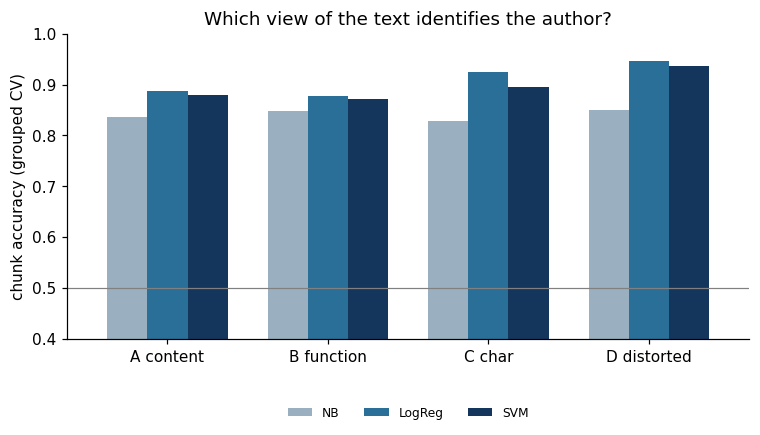

In [24]:
# table of all 12 conditions (computed in sections 5.1-5.3)
results = pd.DataFrame(RESULTS.values())
display(results.style.format(precision=3)
        .background_gradient(subset=["chunk acc", "F1", "chunk AUC", "doc acc"], cmap="Blues").hide(axis="index"))

# plotting chunk accuracy per view and model
pivot = results.pivot_table(index="view", columns="model", values="chunk acc")[["NB", "LogReg", "SVM"]]
ax = pivot.plot.bar(figsize=(8, 3.6), color=[MODEL_COLORS[m] for m in pivot.columns], rot=0, width=0.75)
ax.axhline(0.5, color="grey", lw=0.8); ax.set_ylim(0.4, 1.0)
ax.set_ylabel("chunk accuracy (grouped CV)"); ax.set_xlabel(""); ax.set_title("Which view of the text identifies the author?")
ax.legend(ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.3), frameon=False)
plt.savefig(FIG / "views_models.png", bbox_inches="tight"); plt.show()

1. **Everything beats chance by a wide margin.** Even the weakest condition (Naive Bayes on character n-grams, 0.829) attributes 92% of documents. Two authors with ~75,000 words each is the easy end of authorship attribution, which is why the controls matter more than the headline accuracy.
2. **The distorted view wins.** For both discriminative models it beats the content-word view by 6 points (0.946 vs. 0.887; 0.936 vs. 0.879). Under grouped CV every test assignment is new, so topic words learned elsewhere are mostly noise, while punctuation and function-word patterns carry over. Function words alone (B) are weaker, so the punctuation around them carries part of the signal.
3. **Naive Bayes is worst in every view**, by 2–10 points, and always leans towards me (its precision for Pedro is above its recall). The gap is largest on the character views, where overlapping n-grams violate its independence assumption most.
4. **Logistic regression and the SVM are tied** on views B and D, as expected for two linear models that differ only in the loss. On raw character n-grams the SVM falls behind (0.895 vs. 0.926): with 30,000 features and $C=0.5$ it sits near its regularisation cliff.

## 10. Discussion

**How well did it work?** Better than I expected, with a caveat on what "worked" means. Under grouped cross-validation, a logistic regression that never sees a content word attributes all 73 held-out documents and 95% of 300-word chunks. That shows the models separate *these two authors in this dataset*, not that they would recognise either of us in general; with 37 assignments, the honest interval for document accuracy starts at about 0.9. Two authors with plenty of text is an easy problem, so the controls matter more than the headline: (i) masking topic words *improves* attribution, so topic words are not needed; (ii) unmasking barely dents the distorted model, so the separation does not hinge on a few features; and (iii) the fingerprint consists of interpretable habits that pass a paired test across 37 assignments, after correcting for multiple testing.

**Why these results?** The signal is a handful of habits that survive across genres: my connectives (*hence, also, as, which*) and long sentences, against Pedro's first person, causal *because/since*, commas and dashes. Distorted character n-grams capture these habits *and* the punctuation around them, spread over many features, which makes that view the most robust. Naive Bayes loses because overlapping n-grams violate its independence assumption, which also skews its scores towards me. Logistic regression and the SVM tie because they are the same linear model with different losses; the SVM is more sensitive to $C$ and needs more data because its boundary depends only on the support vectors.

**Limitations.**
* *Two authors.* Choosing between two known candidates is the easiest form of the problem; nothing here shows the model could pick me out of a class of 100.
* *Small sample and model selection.* With 37 assignments as the unit, the interval starts at 0.905. I chose the final model after seeing Section 5, so its numbers are slightly optimistic, and I have not tested whether the differences between models are significant.
* *Masked text is not pure style.* Word lengths, punctuation and sentence structure can still differ between genres, and a few stop-word fragments slip through (`co#` for "CO2").
* *Editing tools.* Pedro disclosed Grammarly editing on several assignments, so "Pedro's commas" may partly be Grammarly's.
* *Heuristic cleaning.* A few template sentences may survive, especially in the AH111 documents; the shared-sentence filter and the distorted view limit this but do not eliminate it.

**Ethics.** The same methods could de-anonymise peer reviews, course feedback or pseudonymous writing: 50 words were enough to be right four times out of five. This project uses texts from two consenting authors and reports only aggregate statistics and single words.

**Next steps.** (1) Add more classmates and move from attribution to *verification* ("is this text mine?"), which is what unmasking was designed for. (2) Test whether paraphrasing with an LLM removes the fingerprint. (3) Compare against learned embeddings once we cover neural text models. (4) Test whether the differences are statistically real, with McNemar's test (Dietterich, 1998) between models and a permutation test (Ojala & Garriga, 2010) that swaps the authors of whole documents within assignments. (5) Use a stricter mask that also hides word lengths. (6) Choose the model inside a nested cross-validation, to remove the optimism from selecting it after seeing the results.

## 11. References

* Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3.
* Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923.
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
* Koppel, M., & Schler, J. (2004). Authorship verification as a one-class classification problem. *Proceedings of the 21st International Conference on Machine Learning (ICML)*.
* Mosteller, F., & Wallace, D. L. (1964). *Inference and Disputed Authorship: The Federalist*. Addison-Wesley.
* Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press. (§1.5.4 text preprocessing and TF-IDF; §4.5.5 cross-validation; §4.7.3 bootstrap; §9.3 naive Bayes; §10.2 logistic regression; §17.3 support vector machines.)
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
* Stamatatos, E. (2017). Authorship attribution using text distortion. *Proceedings of EACL 2017*, 1138–1149.
* Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80–83.